# 04 Pilot checks (20 households)

A 20-household pilot. Sections 0 to 3 are deterministic: the sample, the packet generator (fact ledger, linkable records, rendered documents, packet variants, applicant notes), the application form with its tool schemas and monthly conversion, the reader view, the packet oracle and the checker. Sections 4 to 8 score the model calls already made by `experiments/pilot/run_pilot.py` (saved as JSONL under `experiments/pilot/`); this notebook itself makes no model calls.
Sections are numbered; letters mark parts of one section. Each section carries its own header (question, expected, method, result, mismatch, feeds, open questions).
A mismatch with an expected figure is reported as a mismatch and never adjusted.

Code: `src/snapqc/packets.py` (sample, ledger, records, variants, notes, filer input), `src/snapqc/forms.py` (form, schemas, conversion), `src/snapqc/checker.py` (reader view, oracle, checker), `src/snapqc/pilot_score.py` (scoring of the filer and reader outputs, call budget).

**Status: sections 0 to 8 run. Parts that belong to a proposed switch are marked and guarded by it: 4g (provenance schema), 4h (linkability packet), 5c (reader confidence), 8 (budget calculator).**

| Section | Topic | Parts |
|---|---|---|
| 0 | Setup | switches, data |
| 1 | Pilot sample | a error households, b comparison households, c the 20 |
| 2 | Packet generator | a fact ledger, b linkable records, c rendered documents, d variants, e applicant notes, f form, schemas and monthly conversion, g filer input |
| 3 | Gates | a oracle and human-filed benefit, b nothing reveals the true value; variants differ only by removed documents, c packet files, d reader-view format guard, e checker on the human-filed applications |
| 4 | Filers | a scoring rules, b outcome mix, c abstention and silent-error dollars, d benefit error, e conversion errors on complete packets, f escape vs required and note B vs note A, g provenance tags (proposed), h linkability packet (proposed) |
| 5 | Checker and readers | a human-filed recall and precision, b paired difference reader minus checker, c reader confidence (proposed), d AI-filed applications, e re-reads |
| 6 | Format guard | serializer test on the reader inputs sent, human vs AI classifier |
| 7 | Calls | validity, truncation, tokens, credits, time, throughput |
| 8 | Call-budget calculator (proposed) | pilot and full-run plan |

## 0. Setup

`PROPOSED` switches turn on parts that are proposed and not yet agreed: the provenance schema, the linkability packet variant, a reader confidence field and a call-budget calculator (the last two are used in sections 5 and 8).

In [1]:
import json
import re

import numpy as np
import pandas as pd

from snapqc import checker as C
from snapqc import forms as F
from snapqc import packets as P
from snapqc.data import RESULTS, ROOT, load_fy2024, results_dir

PROPOSED = dict(provenance_schema=True, linkability_packet=True, reader_confidence=True, budget_calculator=True)

OUT = results_dir("04-pilot-checks")
PILOT = ROOT / "experiments" / "pilot"
PILOT.mkdir(parents=True, exist_ok=True)
SEED = P.SEED
VARIANTS = [v for v in P.VARIANTS if v != "faithful_linkability" or PROPOSED["linkability_packet"]]
SCHEMAS = [s for s in F.SCHEMAS if s != "provenance" or PROPOSED["provenance_schema"]]

df = load_fy2024()
arm = pd.read_csv(RESULTS / "01-data-checks" / "3d-human-arm.csv", index_col="row")
tiers = F.sua_tiers(df)
len(df), len(arm), VARIANTS, SCHEMAS

(44891,
 616,
 ['complete', 'faithful', 'faithful_linkability'],
 ['required', 'escape', 'provenance'])

## 1. Pilot sample

- **Question:** Which 20 households does the pilot run on?
- **Expected:** 16 error households from the human arm of 616 (01 part 3d), 5 earned, 5 shelter, 3 unearned, 3 utilities, with at least 4 of the 151, at least 2 with DISCOV1 1 or 2 (found from the case record) and at least 2 with AGENCY1 3 or 4 (client withheld or gave incorrect information, IPV referral); 4 comparison households.
- **Method:** Error households: a seeded draw within each fact group (seed 20261114); a draw that misses a constraint is replaced by a draw with the next seed, and the number of draws is logged. Comparison households: single-row-SUA states, outside the 616, AMTERR $56 or less, no MFIP or SSI-CAP unit, drawn with seed 20261114. Both pools drop households where `calc.benefit` on the verified amounts misses `FSBEN` by more than $1, and households whose verified utility amount matches none of the state's allowance tiers ("actual costs": the form asks only which utilities are paid, so it cannot carry such an amount). The QC-correct benefit is `calc.benefit` on the verified amounts.
- **Result:** 20 households: 16 error (earned 5, shelter 5, unearned 3, utilities 3) and 4 comparison. The seventh draw met the constraints (seed 20261120): 4 of the 151, 3 with DISCOV1 1 or 2, 7 with AGENCY1 3 or 4. Exclusions: the calculator misses `FSBEN` for none of the 601 error households in the four groups or the 31,201 comparison candidates; "actual costs" removes 5 and 180. `calc.benefit` on the verified amounts equals `FSBEN` within $1 for all 20 (one household, 15847, differs by $1). 4 of the 16 have a verified value of $0 in the group in error (all 3 utility errors and 1 shelter error): the household reported a cost it does not have, so the group has no fact and no variant can leave it undocumented. In the pool this holds for 35 of 68 utility errors and 40 of 191 shelter errors. Comparison households: 3 of 4 have one member, 2 are in Nevada, all 4 are on the HCSUA; their issued benefit differs from the QC-correct one by $0 to $27 (AMTERR $56 or less).
- **Mismatch:** None with the expected counts.
- **Feeds:** `rq.md` RQ1 (the households the pilot reads); Households.
- **Open questions:** whether to require a non-zero verified value in the group in error (otherwise the faithful packet of such a household equals the complete one); whether to spread the comparison households over sizes and states.

In [2]:
households, draw_log = P.pilot_sample(df, arm, SEED)
households.to_csv(PILOT / "households.csv")
SAMPLE_COLUMNS = ["kind", "group", "in_151", "DISCOV1", "AGENCY1", "state", "size", "qc_benefit", "FSBEN", "RAWBEN",
                  "AMTERR", "filed_value", "verified_value", "utility_tier"]
households[SAMPLE_COLUMNS].to_csv(OUT / "1-sample.csv")
pd.Series(draw_log).to_frame("value").to_csv(OUT / "1-draw-log.csv")
pd.Series(draw_log).to_frame("value")

,value
error pool (four groups),601
error pool: calculator misses FSBEN,0
error pool: actual utility costs,5
draws,7
seed used,20261120
in_151,4
DISCOV1 1 or 2,3
AGENCY1 3 or 4,7
comparison pool,31201
comparison pool: calculator misses FSBEN,0


### 1a. Error households

The 16 by fact group, with the three constraints counted. Households whose verified value of the group in error is $0 have no fact in that group, so no variant can leave it undocumented: the packet never documents it.

In [3]:
err = households[households.kind == "error"]
summary = pd.DataFrame({
    "households": err.groupby("group").size(),
    "in the 151": err.groupby("group").in_151.sum(),
    "DISCOV1 1 or 2": err.groupby("group").DISCOV1.apply(lambda s: s.isin(P.FROM_CASE_RECORD).sum()),
    "AGENCY1 3 or 4": err.groupby("group").AGENCY1.apply(lambda s: s.isin(P.CLIENT_IPV).sum()),
    "verified value $0": err.groupby("group").verified_value.apply(lambda s: (s == 0).sum()),
}).reindex(list(P.STRATA))
summary.loc["all"] = summary.sum()
summary.to_csv(OUT / "1a-error-households.csv")
summary

,households,in the 151,DISCOV1 1 or 2,AGENCY1 3 or 4,verified value $0
group,,,,,
earned,5,2,1,0,0
shelter,5,0,0,4,1
unearned,3,2,2,1,0
utilities,3,0,0,2,3
all,16,4,3,7,4


In [4]:
# How often the verified value of the group in error is $0 in the human arm (the pool the 16 come from).
pool = arm[arm.group.isin(P.STRATA)]
(pool.verified_value == 0).groupby(pool.group).agg(["sum", "size"]).rename(columns={"sum": "verified $0", "size": "households"})

,verified $0,households
group,,
earned,2,211
shelter,40,191
unearned,3,131
utilities,35,68


### 1b. Comparison households

In [5]:
households[households.kind == "comparison"][SAMPLE_COLUMNS]

,kind,group,in_151,DISCOV1,AGENCY1,state,size,qc_benefit,FSBEN,RAWBEN,AMTERR,filed_value,verified_value,utility_tier
row,,,,,,,,,,,,,,
34791,comparison,,False,<NA>,10,Kansas,1,23.0,23,50,27,NaN,NaN,HCSUA
9052,comparison,,False,<NA>,<NA>,New Jersey,1,291.0,291,285,6,NaN,NaN,HCSUA
42777,comparison,,False,<NA>,1,Nevada,4,225.0,225,252,27,NaN,NaN,HCSUA
42362,comparison,,False,<NA>,<NA>,Nevada,1,23.0,23,23,0,NaN,NaN,HCSUA


### 1c. The 20

In [6]:
households[SAMPLE_COLUMNS]

,kind,group,in_151,DISCOV1,AGENCY1,state,size,qc_benefit,FSBEN,RAWBEN,AMTERR,filed_value,verified_value,utility_tier
row,,,,,,,,,,,,,,
5744,error,earned,False,1,1,Vermont,4,811.0,811,961,150,1023.0,1646.0,HCSUA
15847,error,earned,True,3,1,Mississippi,3,496.0,495,766,271,0.0,1139.0,none
28066,error,earned,False,3,1,Arkansas,1,23.0,23,124,101,73.0,382.0,none
28402,error,earned,False,4,1,Louisiana,4,589.0,589,773,184,650.0,1161.0,none
14542,error,earned,True,3,1,Georgia,2,23.0,23,535,512,0.0,4167.0,HCSUA
9749,error,shelter,False,3,4,Pennsylvania,2,152.0,152,315,163,1402.0,859.0,HCSUA
42865,error,shelter,False,6,4,Nevada,4,458.0,457,618,160,1134.0,600.0,HCSUA
30966,error,shelter,False,3,4,Oklahoma,1,165.0,165,225,60,648.0,450.0,HCSUA
21739,error,shelter,False,6,4,Iowa,2,223.0,223,294,71,735.0,500.0,HCSUA


## 2. Packet generator

- **Question:** Can every pilot household be turned into a packet whose documents carry its verified values, with the error's fact group left undocumented the way the QC record suggests?
- **Expected:** one fact per person x income type with an amount above $0, plus rent and the utility allowance; person-level amounts add up to `FSEARN` and `FSUNEARN` for all 20; every monthly conversion of a pay stub within $1 of the verified amount.
- **Method:** The fact ledger is read from the QC-verified values; each fact gets an id (f01, ...) and a fact group. Amounts outside the four groups (dependent care, medical, child support paid, the homeless deduction) stay fixed calculator inputs and are not on the form or in the packet. Each fact is rendered as records under the linkability rules in part 2b (seeded per household: names, employers, pay frequency, taxes, dates, bill amounts, neutral transactions). Variants keep or drop the records of whole facts (part 2d). Notes A and B in part 2e. The form mirrors the income, housing and utility parts of Michigan's MDHHS-1171 (part 2f).
- **Result:** 63 facts (earned 10, unearned 26, shelter 14, utilities 13); person-level income adds up to `FSEARN` and `FSUNEARN` for all 20, and every group's facts add up to its verified value. 9 wage facts; converting the pay-stub gross back to a monthly amount is within $0.02 of the verified amount for all 9. The faithful variant leaves a group undocumented in 9 of 16 error households (the other 7: 3 with DISCOV1 1 or 2, 4 with a verified $0 in the group in error) and in 4 of 4 comparison households; the linkability variant in 3 error and 1 comparison household. Largest filer input: 6,537 characters, about 1,630 tokens (household 5744, complete, 34 documents); median about 2,370 characters for the complete packets. Tool JSON: about 550 tokens (required), 670 (escape), 1,170 (provenance).
- **Mismatch:** None.
- **Feeds:** `rq.md` RQ1 (packets, applications).
- **Open questions:** 8 of the 41 states have no LUA amount in the file (Connecticut, Michigan, Minnesota, Mississippi, Missouri, Nebraska, New Jersey, South Carolina): a filer there reporting only non-heating utilities gets $0 under the current rule. California's LUA mode rests on 2 households. The human-filed utilities value is the rebuilt amount, which matches no tier amount in 2 of the 3 utility errors ($579 in Nebraska, HCSUA $580; $396 in Nevada, HCSUA $412, LUA $350). The benefit-notice record for unearned types not named in the design is our choice; the income labels are written from the variable names, not quoted from the codebook. The filer instructions are a draft.

In [7]:
shares = P.record_shares()
cases = {}
for row, h in households.iterrows():
    sua = {k: (None if pd.isna(v) else float(v)) for k, v in tiers.loc[h.state].items()}
    cases[row] = P.build_case(df.loc[row], h, sua)
pd.Series(shares, name="share found from the case record (DISCOV1 1 or 2)").to_frame()

,share found from the case record (DISCOV1 1 or 2)
earned,0.113
unearned,0.046
shelter,0.026
utilities,0.044


### 2a. Fact ledger

One row per fact. The utility fact carries the allowance tier inferred from the verified `UTIL` (matched to the state's tier amounts, which are modes of `UTIL` by SUA1 code; the code labels are not verified) and the utility types that tier implies.

In [8]:
facts = pd.DataFrame([{"row": r, **f} for r, c in cases.items() for f in c["facts"]])
facts["link"] = facts["type"].map(P.LINK).fillna(facts["group"].map({"shelter": "lease", "utilities": "bills"}))
facts[["row", "fact", "group", "type", "person", "amount", "utility_types", "link", "employer"]].to_csv(OUT / "2-ledger.csv", index=False)

# Every fact group adds up to the verified group value (person-level sums are asserted inside `ledger`).
totals = facts.groupby(["row", "group"]).amount.sum().unstack().reindex(columns=F.GROUPS).fillna(0)
verified = households[[f"verified_{g}" for g in F.GROUPS]].set_axis(F.GROUPS, axis=1)
assert np.allclose(totals.reindex(verified.index).fillna(0), verified, atol=1)
print(len(facts), "facts;", facts.groupby("group").size().to_dict())
facts[["row", "fact", "group", "type", "person", "amount", "utility_types", "link"]]

63 facts; {'earned': 10, 'shelter': 14, 'unearned': 26, 'utilities': 13}


,row,fact,group,type,person,amount,utility_types,link
0,5744,f01,earned,WAGES,1,1171.0,NaN,payroll
1,5744,f02,earned,WAGES,2,475.0,NaN,payroll
2,5744,f03,unearned,CSUPRT,1,100.0,NaN,state_disbursement
3,5744,f04,shelter,RENT,1,900.0,NaN,lease
4,5744,f05,utilities,HCSUA,1,1020.0,"[Heat, Electricity]",bills
...,...,...,...,...,...,...,...,...
58,42777,f02,unearned,CSUPRT,1,1061.0,NaN,state_disbursement
59,42777,f03,shelter,RENT,1,1589.0,NaN,lease
60,42777,f04,utilities,HCSUA,1,412.0,"[Heat, Electricity]",bills
61,42362,f01,earned,WAGES,1,2280.0,NaN,payroll


### 2b. Linkable records

Which record each source leaves where an agent can retrieve it (`packets.LINK`). Wages: pay stubs from the payroll connector and net pay deposits in the bank feed. Social Security and SSI: an award letter in the drive and a monthly bank deposit. Child support: a monthly bank deposit labelled as a state disbursement. Other agency or payer benefits not named in the design (unemployment, TANF, veterans and similar): the payer's benefit notice in the drive and a monthly bank deposit (our choice). Self-employment, odd jobs, room rental, contributions, deemed, other and unknown income: no linkable record; the complete packet still carries a monthly income record for them in the drive, which the linkability variant drops. Rent: a lease in the drive and a monthly bank payment to the landlord. Utilities: one bill per utility type in the drive. No tax connector.

In [9]:
link = pd.Series(P.LINK, name="record").rename_axis("income type").to_frame()
link["label"] = link.index.map(P.INCOME_LABEL)
link["in the pilot ledger"] = link.index.isin(facts["type"])
link.to_csv(OUT / "2b-linkability.csv")
link[link["in the pilot ledger"]]

,record,label,in the pilot ledger
income type,,,
WAGES,payroll,wages,True
SOCSEC,award_letter,Social Security benefits,True
SSI,award_letter,Supplemental Security Income (SSI),True
CSUPRT,state_disbursement,child support,True
SLFEMP,none,self-employment income (net of business costs),True
CONT,none,help with money from a relative,True
OTHUN,none,other income,True
UNEMP,benefit_notice,unemployment benefits,True
WCOMP,benefit_notice,workers' compensation,True


### 2c. Rendered documents

Pay stubs: gross, federal and state income tax, Social Security and Medicare, health insurance, net, year-to-date gross, pay date, pay frequency and employer, for every pay date from 2026-09-01 to 2026-10-31. The per-period gross is the verified monthly amount divided by the monthly factor of a seeded frequency (weekly, biweekly, semi-monthly, monthly), rounded to cents. The bank feed shows net deposits only. Bills show the utility type and an amount due; under an allowance the bill amount does not enter the benefit. Neutral transactions (groceries, a transfer from the household's own savings, a retail refund) cannot change any amount.

The check below converts each job's per-period gross back to a monthly amount.

In [10]:
stub_check = []
for r, c in cases.items():
    for f in c["facts"]:
        if f["type"] != "WAGES":
            continue
        stubs = [x["data"] for x in c["records"] if x["fact"] == f["fact"] and x["kind"] == "pay_stub"]
        freq = C.FREQUENCY_CODE[stubs[0]["Pay frequency"]]
        stub_check.append({"row": r, "fact": f["fact"], "verified monthly": f["amount"], "frequency": freq,
                           "stubs": len(stubs), "gross per period": stubs[0]["Gross pay"],
                           "monthly from stubs": round(stubs[0]["Gross pay"] * F.MONTHLY_FACTOR[freq], 2)})
stub_check = pd.DataFrame(stub_check)
stub_check["difference"] = (stub_check["monthly from stubs"] - stub_check["verified monthly"]).round(2)
assert stub_check["difference"].abs().max() < 1
stub_check.to_csv(OUT / "2c-stub-conversion.csv", index=False)
stub_check

,row,fact,verified monthly,frequency,stubs,gross per period,monthly from stubs,difference
0,5744,f01,1171.0,Mo,2,1171.00,1171.00,0.00
1,5744,f02,475.0,Wk,9,110.47,475.02,0.02
2,15847,f01,1139.0,2Wks,4,529.77,1139.01,0.01
3,28066,f01,382.0,2Wks,5,177.67,381.99,-0.01
4,28402,f01,1161.0,2x/Mo,4,580.50,1161.00,0.00
5,14542,f01,4167.0,2x/Mo,4,2083.50,4167.00,0.00
6,42865,f01,2534.0,Wk,9,589.30,2533.99,-0.01
7,42777,f01,3484.0,2x/Mo,4,1742.00,3484.00,0.00
8,42362,f01,2280.0,2x/Mo,4,1140.00,2280.00,0.00


### 2d. Variants

- **complete:** every fact has its records.
- **faithful:** for an error household, the facts of the group in error have no records unless DISCOV1 is 1 or 2 (the error was found from the case record). For a comparison household, one non-zero fact group (seeded) loses its records with probability 1 minus the share of that group's errors found from the case record (01 part 5).
- **faithful_linkability** (proposed, behind `PROPOSED["linkability_packet"]`): only the facts with no linkable record are missing.

Document ids are numbered after removal, so a gap in the numbering cannot show where a document was taken out. `undocumented_groups` and `missing_facts` are kept with each packet for scoring and never rendered.

In [11]:
packets = {(r, v): P.make_packet(c, v, shares) for r, c in cases.items() for v in VARIANTS}
variants = pd.DataFrame([{"row": r, "variant": v, "kind": households.at[r, "kind"], "group": households.at[r, "group"],
                          "documents": len(p["documents"]), "undocumented groups": ", ".join(p["undocumented_groups"]),
                          "missing facts": ", ".join(p["missing_facts"])} for (r, v), p in packets.items()])
variants.to_csv(OUT / "2d-variants.csv", index=False)
variants.pivot(index="row", columns="variant", values="undocumented groups").reindex(households.index)

variant,complete,faithful,faithful_linkability
row,,,
5744,,,
15847,,earned,
28066,,earned,
28402,,earned,
14542,,earned,
9749,,shelter,"earned, unearned"
42865,,shelter,
30966,,shelter,
21739,,shelter,


In [12]:
# Packets per variant with at least one undocumented group.
variants.assign(any=variants["undocumented groups"] != "").groupby(["variant", "kind"])["any"].agg(["sum", "size"])

sum  size
variant              kind                 
complete             comparison    0     4
                     error         0    16
faithful             comparison    4     4
                     error         9    16
faithful_linkability comparison    1     4
                     error         3    16

### 2e. Applicant notes

Version A names every fact the household has (people, jobs, benefits, rent, utility types) and gives no amounts. Version B adds, for each undocumented group, the verified monthly amount of its missing facts rounded to the nearest $50 (at least $50): what an applicant who roughly knows the figure would say. For a packet with nothing undocumented, A and B are the same.

In [13]:
notes = {(r, v, n): P.note(cases[r], p, n) for (r, v), p in packets.items() for n in "AB"}
example = next(r for r in households.index if packets[(r, "faithful")]["undocumented_groups"])
print("Version A:\n" + notes[(example, "faithful", "A")] + "\n\nVersion B:\n" + notes[(example, "faithful", "B")])

Version A:
Hi, my name is Alex Mendez. I live with Avery (19) and Harper (14). There are 3 of us applying for food assistance. Avery works at Brightpath Call Center. I get child support.

Version B:
Hi, my name is Alex Mendez. I live with Avery (19) and Harper (14). There are 3 of us applying for food assistance. Avery works at Brightpath Call Center. I get child support. I'd put the wages at about $1,150 a month before taxes.


### 2f. Form, schemas and monthly conversion

The form (`forms.application_schema`) mirrors MDHHS-1171 (Rev. 10-26), text file lines 335-341 (self-employment), 342-356 (employment: employer, average hours per week, wages/tips before tax, per Hr/Wk/2Wks/2x/Mo/Mo/Yr), 357-374 (additional income: type, amount, per Wk/2Wks/2x/Mo/Mo/Yr), 833-851 (housing expenses: type, amount, how often) and 859-876 (utilities paid, by type, no amounts). Three schemas for one forced `submit_application` call: **required** (every money field a number), **escape** (a number or "insufficient_evidence") and **provenance** (proposed: as escape, plus a `source` tag in retrieved_record, applicant_stated, agent_inferred and the `document_ids` the value rests on). Average hours per week and the utility types are wrapped the same way as money fields.

Agency-side conversion (`forms.to_monthly`): per-period amount x factor; an hourly rate x hours per week x 4.3; yearly / 12; a group holding "insufficient_evidence" stays in that state (not $0); blank or missing is $0. Utilities: the state's allowance tier for the utility types reported, by the same rule the oracle uses (heat or air conditioning: HCSUA; any other utility except the phone: LUA; the phone alone: TUA).

**Conversion rule.** 7 CFR 273.10(c)(2)(i), read from the eCFR versioner API, version dated 2026-11-01 (`https://www.ecfr.gov/api/versioner/v1/full/2026-11-01/title-7.xml?part=273&section=273.10`):

> (2) Income only in month received. (i) Income anticipated during the certification period shall be counted as income only in the month it is expected to be received, unless the income is averaged. Whenever a full month's income is anticipated but is received on a weekly or biweekly basis, the State agency shall convert the income to a monthly amount by multiplying weekly amounts by 4.3 and biweekly amounts by 2.15, use the State Agency's PA conversion standard, or use the exact monthly figure if it can be anticipated for each month of the certification period. Nonrecurring lump-sum payments shall be counted as a resource starting in the month received and shall not be counted as income.

The rule gives factors only for weekly (4.3) and biweekly (2.15) pay. Twice a month (x 2), monthly (x 1) and yearly (/ 12) are used here as the exact monthly figure of a fixed amount paid on a fixed schedule; the rule names no factor for them. An hourly rate is converted as rate x hours per week x 4.3; that is our rule, not the CFR text (open question). States may instead use their PA conversion standard; the pilot does not.

In [14]:
pd.Series(F.MONTHLY_FACTOR, name="monthly factor").to_frame()

,monthly factor
Wk,4.300000
2Wks,2.150000
2x/Mo,2.000000
Mo,1.000000
Yr,0.083333


In [15]:
tools = {s: F.tool(s) for s in SCHEMAS}
for s, t in tools.items():
    (PILOT / f"tool-{s}.json").write_text(json.dumps(t, indent=1))
pd.DataFrame({s: {"characters": len(json.dumps(t)), "approx. tokens": len(json.dumps(t)) // 4} for s, t in tools.items()}).T

,characters,approx. tokens
required,2200,550
escape,2676,669
provenance,4685,1171


In [16]:
# Conversion examples: an hourly job, a yearly amount, a biweekly job and an escaped unearned item.
sua_mi = {k: float(v) if pd.notna(v) else None for k, v in tiers.loc["Michigan"].items()}
example_form = {
    "household_size": 2,
    "employment": [{"who": "A", "employer": "X", "avg_hours_per_week": 20, "wages_before_tax": 15, "per": "Hr"},
                   {"who": "B", "employer": "Y", "avg_hours_per_week": 30, "wages_before_tax": 800, "per": "2Wks"}],
    "self_employment": [],
    "additional_income": [{"who": "A", "type_of_income": "pension", "amount": 6000, "per": "Yr"}],
    "housing_expenses": [{"type_of_expense": "Rent", "amount": 750, "how_often": "Mo"}],
    "utilities_paid": ["Heat", "Electricity"],
}
escaped = {**example_form, "additional_income": [{"who": "A", "type_of_income": "pension", "amount": F.ESCAPE, "per": "Yr"}]}
assert F.validate(example_form, "required") == [] and F.validate(escaped, "required") != []
assert F.validate(escaped, "escape") == []
pd.DataFrame({"as filed": F.to_monthly(example_form, sua_mi), "unearned escaped": F.to_monthly(escaped, sua_mi)}).T

,earned,unearned,shelter,utilities
as filed,3010.0,500.0,750.0,680.0
unearned escaped,3010.0,insufficient_evidence,750.0,680.0


### 2g. Filer input

The text a filer receives for one (household, variant, note): the state, the applicant's note and the packet pre-fetched, rendered as results from named connectors, each document with an id the provenance schema can cite. The filer instructions (`packets.FILER_INSTRUCTIONS`) are a draft; the tool JSON per schema is saved as `experiments/pilot/tool-<schema>.json`. All packets, notes and filer inputs are saved to `experiments/pilot/packets.jsonl`.

In [17]:
filer_inputs = {(r, v, n): P.filer_input(packets[(r, v)], notes[(r, v, n)]) for (r, v, n) in notes}
sizes = pd.Series({k: len(t) for k, t in filer_inputs.items()}, name="characters")
sizes.index.names = ["row", "variant", "note"]
size_table = sizes.groupby("variant").describe()[["count", "min", "50%", "max"]]
size_table["max approx. tokens (chars / 4)"] = size_table["max"] // 4
size_table.to_csv(OUT / "2g-filer-input-size.csv")
with open(PILOT / "packets.jsonl", "w") as fh:
    for (r, v), p in packets.items():
        fh.write(json.dumps({**p, "notes": {n: notes[(r, v, n)] for n in "AB"},
                             "filer_input": {n: filer_inputs[(r, v, n)] for n in "AB"}}) + "\n")
print("largest filer input:", sizes.idxmax(), sizes.max(), "characters, about", sizes.max() // 4, "tokens")
size_table

largest filer input: (np.int64(5744), 'complete', 'A') 6537 characters, about 1634 tokens


,count,min,50%,max,max approx. tokens (chars / 4)
variant,,,,,
complete,40.0,964.0,2373.5,6537.0,1634.0
faithful,40.0,825.0,1618.5,6537.0,1634.0
faithful_linkability,40.0,964.0,2165.0,6537.0,1634.0


In [18]:
print(P.FILER_INSTRUCTIONS + "\n\n" + filer_inputs[(example, "faithful", "B")])

You are filling out a SNAP (food assistance) application for the household below. Use the applicant's note and the records the connectors returned. Submit the form by calling submit_application exactly once.

State: Mississippi

Applicant's note:
Hi, my name is Alex Mendez. I live with Avery (19) and Harper (14). There are 3 of us applying for food assistance. Avery works at Brightpath Call Center. I get child support. I'd put the wages at about $1,150 a month before taxes.

Connector results (retrieved for this application):

payroll connector returned 0 pay stubs.

bank connector returned 6 transactions for checking account ****9027, 2026-09-01 to 2026-10-31:
[doc-01] 2026-09-03 | credit $69.17 | TRANSFER FROM SAVINGS ****9027 (OWN ACCOUNT)
[doc-02] 2026-09-07 | debit $87.56 | GROCERY CORNER GROCERY
[doc-03] 2026-09-10 | credit $187.00 | STATE CHILD SUPPORT DISBURSEMENT UNIT
[doc-04] 2026-10-10 | credit $187.00 | STATE CHILD SUPPORT DISBURSEMENT UNIT
[doc-05] 2026-10-22 | debit $109.

## 3. Gates

- **Question:** Is the packet generator safe to run filers and readers on?
- **Expected:** (a) the oracle on the complete packet reproduces the QC-correct benefit within $1 for 20 of 20, and the human-filed application reproduces the issued benefit `RAWBEN` within $1 for 16 of 16; (b) no rendered text names which value is true (0 hits) and the faithful and linkability packets differ from the complete packet only by removed documents; (c) one readable file per packet; (d) the reader view of a human-filed and an AI-filed application have the same keys, order and number format.
- **Method:** (a) `checker.oracle` reads only the rendered documents of the complete packet (stubs: gross per period x factor; award letters and notices; income records; child-support deposits; lease; bills: allowance tier) and `packets.benefit_of` runs `calc.benefit` with those amounts and the household's fixed verified inputs. (b) A case-insensitive scan of every filer input (notes A and B), every reader view and every document field name for: verified, QC, correct, true, error, actual, filed, oracle, ledger, fact, and fact ids (f01, ...); then a multiset comparison of documents (ignoring ids) between variants. (c) Files under `results/04-pilot-checks/packets/`. (d) An assertion on two reader views. (e) The checker on the human-filed applications, for information.
- **Result:** (a) pass: the oracle on the complete packet gives the QC-correct benefit within $1 for 20 of 20 (19 exactly; household 15847 at $495 against $496, where `FSBEN` is $495), and the human-filed application gives `RAWBEN` exactly for 16 of 16. (b) pass: 0 hits in 244 texts (120 filer inputs, 60 reader views, 60 sets of field names, the instructions and 3 tool schemas); for all 20 households the faithful and linkability packets equal the complete packet minus the records of their missing facts. (c) pass: 60 files. (d) pass. (e) On the complete packet the checker flags the group in error for 16 of 16 error households and nothing on the 4 comparison households. On the faithful packet it misses 3 of 16 (15847, 14542, 15436): all three are among the 151, filed $0 for a group the packet leaves undocumented, so the group is out of the checker's scope; it flags the comparison household's undocumented group in 4 of 4.
- **Mismatch:** None with the expected figures.
- **Feeds:** `rq.md` RQ1 (checker and reader inputs).
- **Open questions:** the checker's scope rule leaves a group filed at $0 with no document unflagged (3 of the 16 on the faithful packet); options are to keep the rule, to bring into scope every group the applicant's note names, or to report these as misses by design.

### 3a. Oracle and human-filed benefit

In [19]:
gate_a = []
for r, h in households.iterrows():
    o = C.oracle(packets[(r, "complete")])
    human = P.human_filed(h)
    gate_a.append({"row": r, "kind": h.kind, "group": h.group, "qc_benefit": h.qc_benefit,
                   "oracle_benefit": P.benefit_of(o, h), "RAWBEN": h.RAWBEN, "human_filed_benefit": P.benefit_of(human, h),
                   **{f"oracle_{g}": o[g] for g in F.GROUPS}})
gate_a = pd.DataFrame(gate_a).set_index("row")
gate_a["oracle_pass"] = (gate_a.oracle_benefit - gate_a.qc_benefit).abs() <= 1
gate_a["human_pass"] = np.where(gate_a.kind == "error", (gate_a.human_filed_benefit - gate_a.RAWBEN).abs() <= 1, np.nan)
gate_a.to_csv(OUT / "3a-oracle-gate.csv")
print("oracle within $1 of the QC-correct benefit:", int(gate_a.oracle_pass.sum()), "of", len(gate_a))
err_a = gate_a[gate_a.kind == "error"]
print("human-filed within $1 of RAWBEN:", int(err_a.human_pass.sum()), "of", len(err_a))
gate_a[["kind", "group", "qc_benefit", "oracle_benefit", "oracle_pass", "RAWBEN", "human_filed_benefit", "human_pass"]]

oracle within $1 of the QC-correct benefit: 20 of 20
human-filed within $1 of RAWBEN: 16 of 16


,kind,group,qc_benefit,oracle_benefit,oracle_pass,RAWBEN,human_filed_benefit,human_pass
row,,,,,,,,
5744,error,earned,811.0,811.0,True,961,961.0,1.0
15847,error,earned,496.0,495.0,True,766,766.0,1.0
28066,error,earned,23.0,23.0,True,124,124.0,1.0
28402,error,earned,589.0,589.0,True,773,773.0,1.0
14542,error,earned,23.0,23.0,True,535,535.0,1.0
9749,error,shelter,152.0,152.0,True,315,315.0,1.0
42865,error,shelter,458.0,458.0,True,618,618.0,1.0
30966,error,shelter,165.0,165.0,True,225,225.0,1.0
21739,error,shelter,223.0,223.0,True,294,294.0,1.0


### 3b. Nothing reveals the true value; variants differ only by removed documents

In [20]:
LEAK = re.compile(r"\b(verified|verif\w*|qc|correct\w*|true|errors?|actual\w*|filed|oracle|ledger|facts?)\b|\bf\d{2}\b",
                  re.IGNORECASE)
texts = {("filer input", *k): t for k, t in filer_inputs.items()}
texts |= {("reader view", r, v, "human"): C.reader_view(P.human_filed(households.loc[r]), p) for (r, v), p in packets.items()}
texts |= {("field names", r, v, "-"): " ".join(sorted({k for d in p["documents"] for k in [*d["data"], d["kind"], d["connector"]]}))
          for (r, v), p in packets.items()}
texts["filer instructions", 0, "-", "-"] = P.FILER_INSTRUCTIONS


def schema_strings(x):
    """Every key and string value of a tool schema (JSON booleans such as `true` are syntax, not text)."""
    if isinstance(x, dict):
        return [s for k, v in x.items() for s in [k, *schema_strings(v)]]
    if isinstance(x, list):
        return [s for v in x for s in schema_strings(v)]
    return [x] if isinstance(x, str) else []


texts |= {("tool", 0, s, "-"): " ".join(schema_strings(t)) for s, t in tools.items()}
hits = pd.DataFrame([{"text": k[0], "row": k[1], "variant": k[2], "note": k[3], "match": m.group(0)}
                     for k, t in texts.items() for m in LEAK.finditer(t)],
                    columns=["text", "row", "variant", "note", "match"])
hits.to_csv(OUT / "3b-leak-scan.csv", index=False)
print(len(texts), "texts scanned;", len(hits), "hits")
hits

244 texts scanned; 0 hits


,text,row,variant,note,match


In [21]:
def doc_key(d):
    return json.dumps([d["connector"], d["kind"], d["data"]], sort_keys=True)


def removed_records(case, missing):
    return sorted(json.dumps([x["connector"], x["kind"], x["data"]], sort_keys=True)
                  for x in case["records"] if x["fact"] in missing)


diff_rows = []
for r in households.index:
    complete = sorted(doc_key(d) for d in packets[(r, "complete")]["documents"])
    for v in VARIANTS[1:]:
        p = packets[(r, v)]
        kept = sorted(doc_key(d) for d in p["documents"])
        rest = list(complete)
        for k in kept:  # multiset difference: complete minus this variant
            rest.remove(k)
        diff_rows.append({"row": r, "variant": v, "documents complete": len(complete), "documents kept": len(kept),
                          "removed": len(rest), "removed are exactly the missing facts' records":
                          sorted(rest) == removed_records(cases[r], p["missing_facts"])})
variant_diff = pd.DataFrame(diff_rows)
variant_diff.to_csv(OUT / "3b-variant-diff.csv", index=False)
assert variant_diff["removed are exactly the missing facts' records"].all()
variant_diff.groupby("variant")[["removed are exactly the missing facts' records"]].agg(["sum", "size"])

removed are exactly the missing facts' records     
                                                                sum size
variant                                                                 
faithful                                                         20   20
faithful_linkability                                             20   20

### 3c. Packet files

One file per household and variant, `results/04-pilot-checks/packets/<row>-<variant>.txt`: a header line for the human reader (not part of any model input), notes A and B, then the documents as a filer and a reader see them.

In [22]:
PACKET_DIR = OUT / "packets"
PACKET_DIR.mkdir(exist_ok=True)
for (r, v), p in packets.items():
    head = (f"# household {r} ({households.at[r, 'kind']}{', ' + households.at[r, 'group'] if households.at[r, 'group'] else ''}), "
            f"variant {v}; undocumented groups: {', '.join(p['undocumented_groups']) or 'none'}\n\n")
    body = (f"Note A:\n{notes[(r, v, 'A')]}\n\nNote B:\n{notes[(r, v, 'B')]}\n\n"
            f"Connector results:\n\n{P.render_documents(p)}\n")
    (PACKET_DIR / f"{r}-{v}.txt").write_text(head + body)
written = sorted(PACKET_DIR.glob("*.txt"))
print(len(written), "files, e.g.", written[0].relative_to(ROOT))

60 files, e.g. results/04-pilot-checks/packets/14542-complete.txt


### 3d. Reader-view format guard

One serializer for every application. A human-filed application (whole dollars, every group filled) and a simulated AI-filed one (provenance schema, cents, one group escaped) must give reader views with the same keys in the same order and the same number format; the escaped group must read "not provided", and no tag, token or document id from the application may appear.

In [23]:
r0 = example
h0, p0 = households.loc[r0], packets[(r0, "faithful")]
ai_form = {
    "household_size": int(h0["size"]),
    "employment": [{"who": "applicant", "employer": "Employer", "avg_hours_per_week": {"value": 32.5, "source": "agent_inferred", "document_ids": []},
                    "wages_before_tax": {"value": 1234.567, "source": "retrieved_record", "document_ids": ["doc-01"]}, "per": "2Wks"}],
    "self_employment": [],
    "additional_income": [{"who": "applicant", "type_of_income": "benefit",
                           "amount": {"value": F.ESCAPE, "source": "applicant_stated", "document_ids": []}, "per": "Mo"}],
    "housing_expenses": [{"type_of_expense": "Rent", "amount": {"value": 912.5, "source": "retrieved_record", "document_ids": ["doc-02"]}, "how_often": "Mo"}],
    "utilities_paid": {"value": ["Heat", "Electricity"], "source": "applicant_stated", "document_ids": []},
}
assert F.validate(ai_form, "provenance") == [], F.validate(ai_form, "provenance")
ai_monthly = F.to_monthly(ai_form, p0["sua"])
human_view = C.reader_view(P.human_filed(h0), p0)
ai_view = C.reader_view(ai_monthly, p0)


def app_lines(view):
    return view.split("\n\nDocuments:")[0].splitlines()[1:]


hv, av = app_lines(human_view), app_lines(ai_view)
NUMBER = re.compile(r"^\$\d{1,3}(,\d{3})*$|^not provided$")
assert [l.split(": ")[0] for l in hv] == [l.split(": ")[0] for l in av] == [C.GROUP_LABEL[g] for g in F.GROUPS]
assert all(NUMBER.match(l.split(": ")[1]) for l in hv + av)
assert "not provided" in ai_view and not re.search(r"insufficient|retrieved_record|applicant_stated|agent_inferred", ai_view)
assert human_view.split("\n\nDocuments:")[1] == ai_view.split("\n\nDocuments:")[1]
pd.DataFrame({"human-filed": hv, "AI-filed (simulated)": av})

,human-filed,AI-filed (simulated)
0,Earned income: $0,"Earned income: $2,654"
1,Unearned income: $187,Unearned income: not provided
2,Shelter costs: $0,Shelter costs: $913
3,Utilities: $0,Utilities: $287


### 3e. Checker on the human-filed applications

For information: the checker's flags on the human-filed application, per variant. On the complete packet it should flag the group in error of every error household and nothing on the comparison households.

In [24]:
flag_rows = []
for (r, v), p in packets.items():
    h = households.loc[r]
    flags = C.check(P.human_filed(h), p, h)
    flag_rows.append({"row": r, "variant": v, "kind": h.kind, "group in error": h.group,
                      "flagged": ", ".join(f["group"] for f in flags), "reasons": "; ".join(f"{f['group']}: {f['reason']}" for f in flags),
                      "group in error flagged": h.group in [f["group"] for f in flags] if h.kind == "error" else np.nan,
                      "other groups flagged": len([f for f in flags if f["group"] != h.group])})
checker_human = pd.DataFrame(flag_rows)
checker_human.to_csv(OUT / "3e-checker-human.csv", index=False)
checker_human.groupby(["variant", "kind"]).agg(households=("row", "size"), error_group_flagged=("group in error flagged", "sum"),
                                                other_flags=("other groups flagged", "sum"))

households error_group_flagged  other_flags
variant              kind                                                   
complete             comparison           4                   0            0
                     error               16                  16            0
faithful             comparison           4                   0            4
                     error               16                  13            0
faithful_linkability comparison           4                   0            0
                     error               16                  15            3

In [25]:
checker_human[checker_human.variant == "complete"][["row", "kind", "group in error", "flagged", "reasons"]]

,row,kind,group in error,flagged,reasons
0,5744,error,earned,earned,earned: documented amount changes the benefit ...
3,15847,error,earned,earned,earned: documented amount changes the benefit ...
6,28066,error,earned,earned,earned: documented amount changes the benefit ...
9,28402,error,earned,earned,earned: documented amount changes the benefit ...
12,14542,error,earned,earned,earned: documented amount changes the benefit ...
15,9749,error,shelter,shelter,shelter: documented amount changes the benefit...
18,42865,error,shelter,shelter,shelter: documented amount changes the benefit...
21,30966,error,shelter,shelter,shelter: documented amount changes the benefit...
24,21739,error,shelter,shelter,shelter: documented amount changes the benefit...
27,16881,error,shelter,shelter,shelter: no document


## 4. Filers

- **Question:** On the 20 households, what do the AI filers put on the form for each fact group: the right number, an abstention, a blank, a wrong number, or a number the packet cannot support? What does that do to the benefit?
- **Expected:** no expected figures (first run). For comparison, the human arm of 616 (01 part 3d) has 563 overissuances and 53 underissuances (STATUS 2 and 3 in `3d-human-arm.csv`).
- **Method:** per AI-filed application x fact group, the filed monthly amount against the verified one and the packet; classes and tolerances in part 4a.
- **Result:** 360 AI-filed applications (200 core, 160 proposed), all with JSON arguments that could be scored (11 fail the schema, 8 needed the runner's repair). No filer makes a conversion error: M is 0 of 1,440 group outcomes, and on the complete packets 314 of 318 documented groups are right; the other 4 are abstentions on one self-employment record (household 9749). On the faithful packet with note A, the group the packet leaves out (26 per schema: 13 households x 2 models) is left blank or $0 under the required schema (24 Z, 2 G) and abstained under escape (25 A, 1 Z; abstention recall 0.96, false abstention 2 of 80). The escape schema changes no number: 183 of 183 groups that carry a number under both schemas carry the same one. With note B, 21 of 26 (escape) and 24 of 26 (provenance) undocumented groups take the note's rounded amount. Benefit: no application on a complete packet is off by more than $56; on the faithful packet with note A 24 of 40 are, under each schema (14 over, 10 under; the 616: 563 over, 53 under). Provenance (proposed): 24 of 25 S or G values carry an honest tag; the one G tagged retrieved_record is a documented part with the undocumented part left off.
- **Mismatch:** none with an expected figure (there is none); the 563 / 53 split matches STATUS in `3d-human-arm.csv` (01 part 3d's note gives 616 but not the split).
- **Feeds:** `rq.md` RQ1 (AI-filed applications: what the reader is asked to catch); Packets; Households.
- **Open questions:** whether the documents need to be harder (no conversion error at all); whether to count an escaped group as $0 in the benefit (done here); how to treat a group with no fact that the filer escaped (every utilities group without a fact under escape and provenance); the self-employment lines ask for income before expenses and expenses, while the record gives a net amount.

### 4a. Scoring rules

Inputs: `experiments/pilot/filers-core.jsonl` (200 calls: required and escape schemas on the complete and faithful packets with note A, and escape on the faithful packet with note B; both filer models) and, behind `PROPOSED["provenance_schema"]`, `filers-proposed.jsonl` (160 jobs: provenance on complete and faithful with note A, faithful with note B and, behind `PROPOSED["linkability_packet"]`, faithful_linkability with note A). One job (provenance, faithful, note A, household 9749, `qwen3.5-397b`) failed on connection errors and was re-run; the final answered record per job id is used.

Every output whose arguments decode as JSON is scored, valid or not (the schema-invalid ones are counted in part 7). Fields sent as a JSON-encoded string are decoded first with the runner's own repair (`run_pilot.decode_strings`, flagged `filer_repaired`). The monthly amount per group is `forms.to_monthly` (the agency-side conversion of part 2f).

Per AI-filed application x fact group, against the group's verified monthly amount (the ledger) and the packet:

| Class | Rule |
|---|---|
| A | abstained: the group holds "insufficient_evidence" |
| Z | blank or $0 |
| R | documented group, filed within $5 of verified |
| M | documented group, filed more than $5 from verified (sub-label: net for gross, wrong period or frequency, averaging over the window, other) |
| S | undocumented group, filed within $5 of the note-B amount (when note B was given) |
| G | undocumented group, any other number (sub-label: documented part only, a multiple of the note-B amount, other) |

Scope: groups with a fact (verified above $0). A group is undocumented when the packet dropped at least one of its facts (`undocumented_groups`); for a group with a documented part (only in the linkability packet), the note-B amount is the documented part plus the rounded missing amount. Groups with no fact (verified $0) are tallied apart: $0, abstained, or a number. Tolerances: $5 on a monthly group amount (rounding of per-period amounts and cents); $56 on the benefit (`data.TOLERANCE`).

In [26]:
from snapqc import pilot_score as S

RUN = S.runner()
fact_group = {r: {f["fact"]: f["group"] for f in c["facts"]} for r, c in cases.items()}

filer_files = ["filers-core.jsonl"] + (["filers-proposed.jsonl"] if PROPOSED["provenance_schema"] else [])
filer_recs = [x for f in filer_files for x in S.final_records(PILOT / f)
              if x["variant"] != "faithful_linkability" or PROPOSED["linkability_packet"]]
assert all(x["input_sha"] == RUN.llm.sha(filer_inputs[(x["row"], x["variant"], x["note"])]) for x in filer_recs)

app_rows, group_rows = [], []
for x in filer_recs:
    r, v = x["row"], x["variant"]
    h, p = households.loc[r], packets[(r, v)]
    app, repaired = RUN.decode_strings(x["parsed"]) if isinstance(x.get("parsed"), dict) else (None, False)
    monthly = F.to_monthly(app, p["sua"]) if app is not None else None
    benefit = P.benefit_of(monthly, h) if monthly else np.nan
    app_rows.append({"app_id": x["app_id"], "model": x["filer"], "schema": x["schema"], "variant": v, "note": x["note"],
                     "row": r, "kind": h.kind, "group in error": h.group, "valid": x["valid"], "repaired": repaired,
                     **{f"filed_{g}": monthly[g] for g in F.GROUPS}, "benefit": benefit, "qc_benefit": h.qc_benefit})
    for g in F.GROUPS:
        verified = float(h[f"verified_{g}"])
        undocumented = g in p["undocumented_groups"]
        documented_part, note_b = S.note_b_amount(cases[r]["facts"], p, g)
        note_b = note_b if x["note"] == "B" else None
        filed = monthly[g]
        c = S.classify(filed, verified, undocumented, note_b)
        sub = (S.m_sublabel(float(filed), g, p) if c == "M" else S.g_sublabel(float(filed), documented_part, note_b)
               if c == "G" else "")
        tag, ids = S.group_tag(app, g) if x["schema"] == "provenance" else (None, [])
        group_rows.append({"app_id": x["app_id"], "model": x["filer"], "schema": x["schema"], "variant": v, "note": x["note"],
                           "row": r, "kind": h.kind, "group": g, "group in error": g == h.group,
                           "undocumented": undocumented, "verified": verified, "filed": filed, "note_b": note_b,
                           "outcome": c, "sub-label": sub, "tag": tag, "document_ids": " ".join(ids),
                           "cited": S.cited_documents(ids, p, fact_group[r], g) if tag else ""})
apps = pd.DataFrame(app_rows)
groups = pd.DataFrame(group_rows)
groups["scope"] = np.where(groups.verified == 0, "no fact", np.where(groups.undocumented, "undocumented", "documented"))
groups["abs error"] = np.where(groups.outcome.isin(["M", "Z", "G"]),
                               (pd.to_numeric(groups.filed, errors="coerce") - groups.verified).abs(), 0.0)
groups.drop(columns="abs error").to_csv(OUT / "4a-filer-groups.csv", index=False)
CELL = ["model", "schema", "variant", "note"]
print(len(apps), "AI-filed applications;", len(groups), "application x group rows;",
      int(apps.repaired.sum()), "repaired;", int((~apps.valid).sum()), "schema-invalid but scored")
apps.groupby(["schema", "variant", "note"]).size().rename("applications").to_frame()

360 AI-filed applications; 1440 application x group rows; 8 repaired; 11 schema-invalid but scored


applications
schema     variant              note              
escape     complete             A               40
           faithful             A               40
                                B               40
provenance complete             A               40
           faithful             A               40
                                B               40
           faithful_linkability A               40
required   complete             A               40
           faithful             A               40

In [27]:
# Employment lines whose hours per week were escaped: `forms.to_monthly` blanks earned income for them only when
# the wage is hourly (per "Hr"); a per-period wage does not use the hours.
hours_escaped = [(x["app_id"], j.get("per")) for x in filer_recs for j in (RUN.decode_strings(x["parsed"])[0].get("employment") or [])
                 if F._value(j.get("avg_hours_per_week")) == F.ESCAPE]
print("employment lines with hours escaped:", len(hours_escaped), "in", len({a for a, _ in hours_escaped}), "applications;",
      "hourly:", sum(per == "Hr" for _, per in hours_escaped))

employment lines with hours escaped: 124 in 110 applications; hourly: 1


In [28]:
# The AI-filed applications the readers saw must carry the same monthly amounts as this scoring.
read_inputs = {a["app_id"]: a for a in S.read_jsonl(PILOT / "reader-inputs.jsonl")}
check_same = [(i, a["app_monthly"], apps.set_index("app_id").loc[i, [f"filed_{g}" for g in F.GROUPS]].tolist())
              for i, a in read_inputs.items() if a["filer"] != "human" and i in set(apps.app_id)]
assert all([m[g] for g in F.GROUPS] == v for _, m, v in check_same), "reader inputs differ from the scored amounts"
len(check_same)

80

### 4b. Outcome mix

Counts per model x schema x packet x note, on the undocumented groups (the group a faithful packet leaves out) and on the documented groups; shares in `4b-outcome-mix.csv`. Groups with no fact are in part 4c.

In [29]:
def mix(d, by):
    t = d.groupby(by).outcome.value_counts().unstack(fill_value=0).reindex(columns=S.OUTCOMES, fill_value=0)
    t["groups"] = t.sum(axis=1)
    return t


in_scope = groups[groups.scope != "no fact"]
mix_rows = []
for scope in ["undocumented", "documented"]:
    t = mix(in_scope[in_scope.scope == scope], CELL)
    for idx, row in t.iterrows():
        mix_rows.append({"scope": scope, **dict(zip(CELL, idx)), "groups": row.groups,
                         **{o: row[o] for o in S.OUTCOMES}, **{f"share {o}": round(row[o] / row.groups, 3) for o in S.OUTCOMES}})
outcome_mix = pd.DataFrame(mix_rows)
outcome_mix.to_csv(OUT / "4b-outcome-mix.csv", index=False)
mix(in_scope[in_scope.scope == "undocumented"], CELL)

outcome                                                  A   Z  R  M   S  G  \
model             schema     variant              note                        
deepseek-v4-flash escape     faithful             A     13   0  0  0   0  0   
                                                  B      1   0  0  0  12  0   
                  provenance faithful             A     13   0  0  0   0  0   
                                                  B      0   0  0  0  13  0   
                             faithful_linkability A      5   0  0  0   0  0   
                  required   faithful             A      0  13  0  0   0  0   
qwen3.5-397b      escape     faithful             A     12   1  0  0   0  0   
                                                  B      3   0  0  0   9  1   
                  provenance faithful             A     12   1  0  0   0  0   
                                                  B      2   0  0  0  11  0   
                             faithful_linkability A      3   1  0  0   0  1   
                  required   faithful             A      0  11  0  0   0  2   

outcome                                                 groups  
model             schema     variant              note          
deepseek-v4-flash escape     faithful             A         13  
                                                  B         13  
                  provenance faithful             A         13  
                                                  B         13  
                             faithful_linkability A          5  
                  required   faithful             A         13  
qwen3.5-397b      escape     faithful             A         13  
                                                  B         13  
                  provenance faithful             A         13  
                                                  B         13  
                             faithful_linkability A          5  
                  required   faithful             A         13

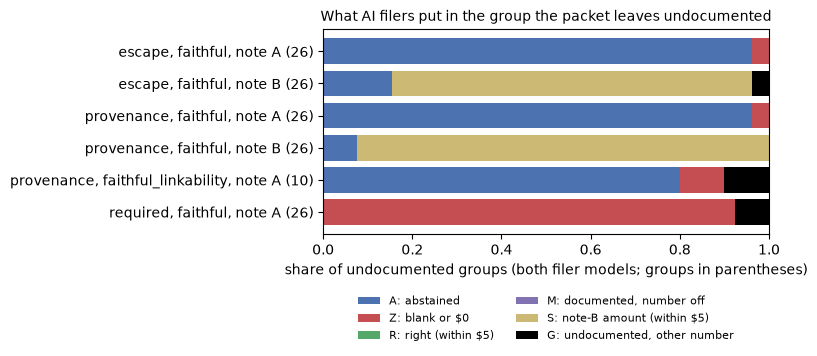

In [30]:
import matplotlib.pyplot as plt

und = in_scope[in_scope.scope == "undocumented"]
fig_mix = mix(und, ["schema", "variant", "note"])
mix_shares = fig_mix[S.OUTCOMES].div(fig_mix.groups, axis=0)
labels = [f"{s}, {v}, note {n} ({k})" for (s, v, n), k in zip(fig_mix.index, fig_mix.groups)]
fig, ax = plt.subplots(figsize=(8, 0.45 * len(mix_shares) + 1.2))
left = np.zeros(len(mix_shares))
colors = {"A": "#4c72b0", "Z": "#c44e52", "R": "#55a868", "M": "#8172b2", "S": "#ccb974", "G": "#000000"}
for o in S.OUTCOMES:
    ax.barh(labels, mix_shares[o], left=left, color=colors[o], label=f"{o}: {S.OUTCOME_LABEL[o]}")
    left += mix_shares[o].to_numpy()
ax.invert_yaxis()
ax.set_xlabel("share of undocumented groups (both filer models; groups in parentheses)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, fontsize=8, frameon=False)
ax.set_title("What AI filers put in the group the packet leaves undocumented", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "4b-outcome-mix-undocumented.svg", bbox_inches="tight")
plt.show()

In [31]:
mix(in_scope[in_scope.scope == "documented"], CELL)

outcome                                                 A  Z   R  M  S  G  \
model             schema     variant              note                      
deepseek-v4-flash escape     complete             A     1  0  52  0  0  0   
                             faithful             A     1  0  39  0  0  0   
                                                  B     1  0  39  0  0  0   
                  provenance complete             A     1  0  52  0  0  0   
                             faithful             A     1  0  39  0  0  0   
                                                  B     1  0  39  0  0  0   
                             faithful_linkability A     0  0  48  0  0  0   
                  required   complete             A     0  0  53  0  0  0   
                             faithful             A     0  0  40  0  0  0   
qwen3.5-397b      escape     complete             A     1  0  52  0  0  0   
                             faithful             A     1  0  39  0  0  0   
                                                  B     1  0  39  0  0  0   
                  provenance complete             A     1  0  52  0  0  0   
                             faithful             A     1  0  39  0  0  0   
                                                  B     1  0  39  0  0  0   
                             faithful_linkability A     0  0  48  0  0  0   
                  required   complete             A     0  0  53  0  0  0   
                             faithful             A     0  0  40  0  0  0   

outcome                                                 groups  
model             schema     variant              note          
deepseek-v4-flash escape     complete             A         53  
                             faithful             A         40  
                                                  B         40  
                  provenance complete             A         53  
                             faithful             A         40  
                                                  B         40  
                             faithful_linkability A         48  
                  required   complete             A         53  
                             faithful             A         40  
qwen3.5-397b      escape     complete             A         53  
                             faithful             A         40  
                                                  B         40  
                  provenance complete             A         53  
                             faithful             A         40  
                                                  B         40  
                             faithful_linkability A         48  
                  required   complete             A         53  
                             faithful             A         40

In [32]:
# Every M and G value with its sub-label, and every Z and A on a documented group.
odd = groups[groups.outcome.isin(["M", "G"]) | (groups.outcome.isin(["Z", "A"]) & (groups.scope == "documented"))]
odd[["app_id", "group", "scope", "verified", "filed", "note_b", "outcome", "sub-label"]].sort_values(["outcome", "app_id"])

,app_id,group,scope,verified,filed,note_b,outcome,sub-label
336,deepseek-v4-flash|escape|complete|A|9749,earned,documented,100.0,insufficient_evidence,NaN,A,
504,deepseek-v4-flash|escape|faithful|A|9749,earned,documented,100.0,insufficient_evidence,NaN,A,
700,deepseek-v4-flash|escape|faithful|B|9749,earned,documented,100.0,insufficient_evidence,NaN,A,
828,deepseek-v4-flash|provenance|complete|A|9749,earned,documented,100.0,insufficient_evidence,NaN,A,
988,deepseek-v4-flash|provenance|faithful|A|9749,earned,documented,100.0,insufficient_evidence,NaN,A,
1164,deepseek-v4-flash|provenance|faithful|B|9749,earned,documented,100.0,insufficient_evidence,NaN,A,
384,qwen3.5-397b|escape|complete|A|9749,earned,documented,100.0,insufficient_evidence,NaN,A,
520,qwen3.5-397b|escape|faithful|A|9749,earned,documented,100.0,insufficient_evidence,NaN,A,
752,qwen3.5-397b|escape|faithful|B|9749,earned,documented,100.0,insufficient_evidence,NaN,A,
888,qwen3.5-397b|provenance|complete|A|9749,earned,documented,100.0,insufficient_evidence,NaN,A,


### 4c. Abstention, false abstention, silent-error dollars; groups with no fact

Abstention recall: A / undocumented groups. False abstention: A / documented groups. Silent-error dollars: |filed - verified| summed over M, Z and G (a group the filer did not flag as unsupported), also per application.

In [33]:
def rates(d):
    und, doc = d[d.scope == "undocumented"], d[d.scope == "documented"]
    return pd.Series({"applications": d.app_id.nunique(),
                      "undocumented groups": len(und), "abstained (undocumented)": int((und.outcome == "A").sum()),
                      "abstention recall": (und.outcome == "A").mean() if len(und) else np.nan,
                      "documented groups": len(doc), "abstained (documented)": int((doc.outcome == "A").sum()),
                      "false abstention": (doc.outcome == "A").mean(),
                      "silent-error dollars": d["abs error"].sum(),
                      "silent-error dollars per application": d["abs error"].sum() / d.app_id.nunique()})


abstention = groups.groupby(CELL).apply(rates)
abstention_schema = groups.groupby(["schema", "variant", "note"]).apply(rates)
pd.concat({"by model": abstention, "both models": abstention_schema.assign(model="both").set_index("model", append=True)
           .reorder_levels(CELL)}).to_csv(OUT / "4c-abstention.csv")
abstention_schema.round(3)

applications  undocumented groups  \
schema     variant              note                                      
escape     complete             A             40.0                  0.0   
           faithful             A             40.0                 26.0   
                                B             40.0                 26.0   
provenance complete             A             40.0                  0.0   
           faithful             A             40.0                 26.0   
                                B             40.0                 26.0   
           faithful_linkability A             40.0                 10.0   
required   complete             A             40.0                  0.0   
           faithful             A             40.0                 26.0   

                                      abstained (undocumented)  \
schema     variant              note                             
escape     complete             A                          0.0   
           faithful             A                         25.0   
                                B                          4.0   
provenance complete             A                          0.0   
           faithful             A                         25.0   
                                B                          2.0   
           faithful_linkability A                          8.0   
required   complete             A                          0.0   
           faithful             A                          0.0   

                                      abstention recall  documented groups  \
schema     variant              note                                         
escape     complete             A                   NaN              106.0   
           faithful             A                 0.962               80.0   
                                B                 0.154               80.0   
provenance complete             A                   NaN              106.0   
           faithful             A                 0.962               80.0   
                                B                 0.077               80.0   
           faithful_linkability A                 0.800               96.0   
required   complete             A                   NaN              106.0   
           faithful             A                 0.000               80.0   

                                      abstained (documented)  \
schema     variant              note                           
escape     complete             A                        2.0   
           faithful             A                        2.0   
                                B                        2.0   
provenance complete             A                        2.0   
           faithful             A                        2.0   
                                B                        2.0   
           faithful_linkability A                        0.0   
required   complete             A                        0.0   
           faithful             A                        0.0   

                                      false abstention  silent-error dollars  \
schema     variant              note                                           
escape     complete             A                0.019                  0.00   
           faithful             A                0.025               2280.00   
                                B                0.025               1917.00   
provenance complete             A                0.019                  0.00   
           faithful             A                0.025                382.00   
                                B                0.025                  0.00   
           faithful_linkability A                0.000               1442.00   
required   complete             A                0.000                  0.00   
           faithful             A                0.000              30980.71   

                                      si

In [34]:
abstention.round(3)

applications  \
model             schema     variant              note                 
deepseek-v4-flash escape     complete             A             20.0   
                             faithful             A             20.0   
                                                  B             20.0   
                  provenance complete             A             20.0   
                             faithful             A             20.0   
                                                  B             20.0   
                             faithful_linkability A             20.0   
                  required   complete             A             20.0   
                             faithful             A             20.0   
qwen3.5-397b      escape     complete             A             20.0   
                             faithful             A             20.0   
                                                  B             20.0   
                  provenance complete             A             20.0   
                             faithful             A             20.0   
                                                  B             20.0   
                             faithful_linkability A             20.0   
                  required   complete             A             20.0   
                             faithful             A             20.0   

                                                        undocumented groups  \
model             schema     variant              note                        
deepseek-v4-flash escape     complete             A                     0.0   
                             faithful             A                    13.0   
                                                  B                    13.0   
                  provenance complete             A                     0.0   
                             faithful             A                    13.0   
                                                  B                    13.0   
                             faithful_linkability A                     5.0   
                  required   complete             A                     0.0   
                             faithful             A                    13.0   
qwen3.5-397b      escape     complete             A                     0.0   
                             faithful             A                    13.0   
                                                  B                    13.0   
                  provenance complete             A                     0.0   
                             faithful             A                    13.0   
                                                  B                    13.0   
                             faithful_linkability A                     5.0   
                  required   complete             A                     0.0   
                             faithful             A                    13.0   

                                                        abstained (undocumented)  \
model             schema     variant              note                             
deepseek-v4-flash escape     complete             A                          0.0   
                             faithful             A                         13.0   
                                                  B                          1.0   
                  provenance complete             A                          0.0   
                             faithful             A                         13.0   
                                                  B                          0.0   
                             faithful_linkability A                          5.0   
                  required   complete             A                          0.0   
                             faithful             A                          0.0   
qwen3.5-397b      escape     complete             A                          0.0   
                          

In [35]:
# Groups with no fact (verified $0): what the filer put there.
zero_fact = (groups[groups.scope == "no fact"].groupby(["schema", "model", "group"]).outcome.value_counts()
             .unstack(fill_value=0).reindex(columns=S.ZERO_FACT, fill_value=0))
zero_fact.to_csv(OUT / "4c-zero-fact-groups.csv")
zero_fact

outcome                                 no fact: $0  no fact: abstained  \
schema     model             group                                        
escape     deepseek-v4-flash earned              33                   0   
                             shelter             18                   0   
                             unearned             9                   0   
                             utilities            0                  21   
           qwen3.5-397b      earned              33                   0   
                             shelter             17                   1   
                             unearned             9                   0   
                             utilities            0                  21   
provenance deepseek-v4-flash earned              44                   0   
                             shelter             24                   0   
                             unearned            12                   0   
                             utilities            0                  28   
           qwen3.5-397b      earned              44                   0   
                             shelter             23                   1   
                             unearned            12                   0   
                             utilities            0                  28   
required   deepseek-v4-flash earned              22                   0   
                             shelter             12                   0   
                             unearned             6                   0   
                             utilities           14                   0   
           qwen3.5-397b      earned              22                   0   
                             shelter             12                   0   
                             unearned             6                   0   
                             utilities           14                   0   

outcome                                 no fact: number  
schema     model             group                       
escape     deepseek-v4-flash earned                   0  
                             shelter                  0  
                             unearned                 0  
                             utilities                0  
           qwen3.5-397b      earned                   0  
                             shelter                  0  
                             unearned                 0  
                             utilities                0  
provenance deepseek-v4-flash earned                   0  
                             shelter                  0  
                             unearned                 0  
                             utilities                0  
           qwen3.5-397b      earned                   0  
                             shelter                  0  
                             unearned                 0  
                             utilities                0  
required   deepseek-v4-flash earned                   0  
                             shelter                  0  
                             unearned                 0  
                             utilities                0  
           qwen3.5-397b      earned                   0  
                             shelter                  0  
                             unearned                 0  
                             utilities                0

### 4d. Benefit error

Benefit per application: `packets.benefit_of` on the filed monthly amounts with the household's fixed verified inputs; a group left at "insufficient_evidence" counts as $0 (the agency gets no amount for it). Error: benefit minus the QC-correct benefit (`households.csv`). Above $56: |error| > $56; over if the filed benefit is higher. The human-filed row is the issued benefit `RAWBEN` of the 16 error households (comparison households: their issued benefit, AMTERR $56 or less).

In [36]:
apps["error"] = apps.benefit - apps.qc_benefit
apps["above $56"] = apps.error.abs() > S.TOL_BENEFIT
apps["direction"] = np.where(~apps["above $56"], "", np.where(apps.error > 0, "over", "under"))
apps.to_csv(OUT / "4d-filer-applications.csv", index=False)


def benefit_summary(d):
    over, under = int((d.direction == "over").sum()), int((d.direction == "under").sum())
    return pd.Series({"applications": len(d), "above $56": over + under, "over": over, "under": under,
                      "share over among above $56": round(over / (over + under), 3) if over + under else np.nan,
                      "mean |error|": round(d.error.abs().mean(), 1), "max |error|": d.error.abs().max()})


human_err = households.assign(error=households.RAWBEN - households.qc_benefit)
human_err["direction"] = np.where(human_err.error.abs() <= S.TOL_BENEFIT, "", np.where(human_err.error > 0, "over", "under"))
arm_status = arm.STATUS.value_counts()  # STATUS 2 overissuance, 3 underissuance
arm_row = pd.Series({"applications": len(arm), "above $56": len(arm), "over": arm_status.get(2, 0), "under": arm_status.get(3, 0),
                     "share over among above $56": round(arm_status.get(2, 0) / len(arm), 3)})
benefit_table = pd.concat([apps.groupby(["schema", "variant", "note"]).apply(benefit_summary),
                           pd.DataFrame({("human-filed", "issued", "-"): benefit_summary(human_err),
                                         ("human arm of 616", "01 part 3d", "-"): arm_row}).T])
benefit_table.to_csv(OUT / "4d-benefit-error.csv")
benefit_table

applications  above $56   over  \
escape           complete             A          40.0        0.0    0.0   
                 faithful             A          40.0       24.0   14.0   
                                      B          40.0        5.0    4.0   
provenance       complete             A          40.0        0.0    0.0   
                 faithful             A          40.0       24.0   14.0   
                                      B          40.0        2.0    2.0   
                 faithful_linkability A          40.0        6.0    6.0   
required         complete             A          40.0        0.0    0.0   
                 faithful             A          40.0       24.0   14.0   
human-filed      issued               -          20.0       16.0   16.0   
human arm of 616 01 part 3d           -         616.0      616.0  563.0   

                                         under  share over among above $56  \
escape           complete             A    0.0                         NaN   
                 faithful             A   10.0                       0.583   
                                      B    1.0                       0.800   
provenance       complete             A    0.0                         NaN   
                 faithful             A   10.0                       0.583   
                                      B    0.0                       1.000   
                 faithful_linkability A    0.0                       1.000   
required         complete             A    0.0                         NaN   
                 faithful             A   10.0                       0.583   
human-filed      issued               -    0.0                       1.000   
human arm of 616 01 part 3d           -   53.0                       0.914   

                                         mean |error|  max |error|  
escape           complete             A           1.8         36.0  
                 faithful             A         135.6        512.0  
                                      B          44.7        575.0  
provenance       complete             A           1.8         36.0  
                 faithful             A         135.6        512.0  
                                      B          11.0        218.0  
                 faithful_linkability A          37.5        383.0  
required         complete             A           0.0          1.0  
                 faithful             A         134.0        512.0  
human-filed      issued               -         136.0        512.0  
human arm of 616 01 part 3d           -           NaN          NaN

In [37]:
# Benefit error by model on the faithful packet.
apps[apps.variant != "complete"].groupby(CELL).apply(benefit_summary)

applications  \
model             schema     variant              note                 
deepseek-v4-flash escape     faithful             A             20.0   
                                                  B             20.0   
                  provenance faithful             A             20.0   
                                                  B             20.0   
                             faithful_linkability A             20.0   
                  required   faithful             A             20.0   
qwen3.5-397b      escape     faithful             A             20.0   
                                                  B             20.0   
                  provenance faithful             A             20.0   
                                                  B             20.0   
                             faithful_linkability A             20.0   
                  required   faithful             A             20.0   

                                                        above $56  over  \
model             schema     variant              note                    
deepseek-v4-flash escape     faithful             A          12.0   7.0   
                                                  B           1.0   1.0   
                  provenance faithful             A          12.0   7.0   
                                                  B           0.0   0.0   
                             faithful_linkability A           3.0   3.0   
                  required   faithful             A          12.0   7.0   
qwen3.5-397b      escape     faithful             A          12.0   7.0   
                                                  B           4.0   3.0   
                  provenance faithful             A          12.0   7.0   
                                                  B           2.0   2.0   
                             faithful_linkability A           3.0   3.0   
                  required   faithful             A          12.0   7.0   

                                                        under  \
model             schema     variant              note          
deepseek-v4-flash escape     faithful             A       5.0   
                                                  B       0.0   
                  provenance faithful             A       5.0   
                                                  B       0.0   
                             faithful_linkability A       0.0   
                  required   faithful             A       5.0   
qwen3.5-397b      escape     faithful             A       5.0   
                                                  B       1.0   
                  provenance faithful             A       5.0   
                                                  B       0.0   
                             faithful_linkability A       0.0   
                  required   faithful             A       5.0   

                                                        share over among above $56  \
model             schema     variant              note                               
deepseek-v4-flash escape     faithful             A                          0.583   
                                                  B                          1.000   
                  provenance faithful             A                          0.583   
                                                  B                            NaN   
                             faithful_linkability A                          1.000   
                  required   faithful             A                          0.583   
qwen3.5-397b      escape     faithful             A                          0.583   
                                                  B                          0.750   
                  provenance faithful             A                          0.583   
                                                  B                          1.000   
                             faithful_linkability A  

### 4e. Conversion errors on complete packets

On a complete packet every group is documented, so a wrong number there is a conversion error (M). No filer, model or schema makes one: 0 M among the 318 documented groups (and 0 among all 1,440 group outcomes). The documents are too easy to produce conversion errors: every stub states its pay frequency, every letter and record states a monthly amount, and no amount has to be averaged over irregular pay. Harder document options are an open question (for example stubs that state only a pay period, hourly pay with varying hours, irregular self-employment receipts, a lease with a mid-period rent change); nothing is tuned on these households.

In [38]:
complete_m = groups[(groups.variant == "complete") & (groups.scope == "documented")]
print("documented groups on complete packets:", len(complete_m), "; M:", int((complete_m.outcome == "M").sum()),
      "; R:", int((complete_m.outcome == "R").sum()), "; A:", int((complete_m.outcome == "A").sum()))
complete_m.groupby(["schema", "model"]).outcome.value_counts().unstack(fill_value=0)

documented groups on complete packets: 318 ; M: 0 ; R: 314 ; A: 4


outcome                       A   R
schema     model                   
escape     deepseek-v4-flash  1  52
           qwen3.5-397b       1  52
provenance deepseek-v4-flash  1  52
           qwen3.5-397b       1  52
required   deepseek-v4-flash  0  53
           qwen3.5-397b       0  53

### 4f. Escape vs required; note B vs note A

Same household, packet and model: the required and the escape output side by side for every group with a fact (complete and faithful packets, note A). "Same number" means within $5.

In [39]:
key = ["model", "variant", "row", "group"]
a = groups[(groups.note == "A") & (groups.scope != "no fact")]
pair = a[a.schema == "required"].set_index(key)[["outcome", "filed", "scope"]].merge(
    a[a.schema == "escape"].set_index(key)[["outcome", "filed"]], left_index=True, right_index=True, suffixes=("", " escape"))
both_numbers = pair[(pair["outcome"] != "A") & (pair["outcome escape"] != "A")]
same = (pd.to_numeric(both_numbers.filed) - pd.to_numeric(both_numbers["filed escape"])).abs() <= S.TOL_GROUP
print("groups with a number under both schemas:", len(both_numbers), "; same number:", int(same.sum()))
escape_vs_required = pd.crosstab([pair.scope, pair.outcome], pair["outcome escape"])
escape_vs_required.to_csv(OUT / "4f-escape-vs-required.csv")
escape_vs_required

groups with a number under both schemas: 183 ; same number: 183


outcome escape         A    R  Z
scope        outcome            
documented   R         4  182  0
undocumented G         2    0  0
             Z        23    0  1

In [40]:
both_numbers[~same]

,,,,outcome,filed,scope,outcome escape,filed escape
model,variant,row,group,,,,,


In [41]:
# Note B vs note A, escape schema, faithful packet, undocumented groups.
fa = groups[(groups.schema == "escape") & (groups.variant == "faithful") & (groups.scope == "undocumented")]
note_ab = pd.crosstab(fa[fa.note == "A"].set_index(["model", "row", "group"]).outcome.rename("note A"),
                      fa[fa.note == "B"].set_index(["model", "row", "group"]).outcome.rename("note B"))
note_ab.to_csv(OUT / "4f-note-b-vs-a.csv")
note_ab

note B,A,G,S
note A,,,
A,4,1,20
Z,0,0,1


### 4g. Provenance tags (proposed: `PROPOSED["provenance_schema"]`)

A group's tag is the strongest claim among its fields that carry a number above $0 (utilities: a non-empty list of types): retrieved_record if any such field says so, else applicant_stated, else agent_inferred (`pilot_score.group_tag`). Honest tag: an S or G value tagged applicant_stated or agent_inferred. Laundering: a G value tagged retrieved_record, split by whether the cited document ids exist in the packet and belong to that group (packet `sources`: document -> fact -> group).

In [42]:
if PROPOSED["provenance_schema"]:
    prov = groups[(groups.schema == "provenance") & (groups.scope != "no fact")]
    tags = (prov[prov.outcome.isin(["R", "M", "S", "G", "Z"])].fillna({"tag": "no field with a number"})
            .groupby(["variant", "note", "outcome"]).tag.value_counts().unstack(fill_value=0))
    tags.to_csv(OUT / "4g-provenance-tags.csv")
    sg = prov[prov.outcome.isin(["S", "G"])]
    honest = sg.tag.isin(["applicant_stated", "agent_inferred"])
    laundered = prov[(prov.outcome == "G") & (prov.tag == "retrieved_record")]
    print("S or G values:", len(sg), "; honest tag:", int(honest.sum()), f"({honest.mean():.0%})" if len(sg) else "")
    print("G values:", int((prov.outcome == "G").sum()), "; tagged retrieved_record:", len(laundered))
    print(laundered[["app_id", "group", "filed", "document_ids", "cited"]].to_string() if len(laundered) else "no laundering")
    display(tags)

S or G values: 25 ; honest tag: 24 (96%)
G values: 1 ; tagged retrieved_record: 1
                                                   app_id     group   filed          document_ids                           cited
1309  qwen3.5-397b|provenance|faithful_linkability|A|9749  unearned  1439.0  doc-03 doc-06 doc-09  cites a document of this group


tag                                agent_inferred  applicant_stated  \
variant              note outcome                                     
complete             A    R                     0                 1   
faithful             A    R                     0                 2   
                          Z                     0                 0   
                     B    R                     0                 3   
                          S                     1                23   
faithful_linkability A    G                     0                 0   
                          R                     0                 3   
                          Z                     0                 0   

tag                                no field with a number  retrieved_record  
variant              note outcome                                            
complete             A    R                             0               103  
faithful             A    R                             0                76  
                          Z                             1                 0  
                     B    R                             0                75  
                          S                             0                 0  
faithful_linkability A    G                             0                 1  
                          R                             0                93  
                          Z                             1                 0

In [43]:
if PROPOSED["provenance_schema"]:
    # Provenance vs escape on the same households, models and packets: abstention and outcome mix, both models.
    same_cells = groups[groups.schema.isin(["escape", "provenance"]) & (groups.variant.isin(["complete", "faithful"]))
                        & (groups.scope != "no fact")]
    prov_vs_escape = mix(same_cells, ["scope", "variant", "note", "schema"])
    prov_vs_escape.to_csv(OUT / "4g-provenance-vs-escape.csv")
    display(prov_vs_escape)
    k2 = ["model", "variant", "note", "row", "group"]
    pe = same_cells[same_cells.schema == "escape"].set_index(k2).outcome.rename("escape").to_frame().join(
        same_cells[same_cells.schema == "provenance"].set_index(k2).outcome.rename("provenance"))
    print("same outcome under escape and provenance:", int((pe.escape == pe.provenance).sum()), "of", len(pe))
    display(pd.crosstab(pe.escape, pe.provenance))

outcome                                 A  Z    R  M   S  G  groups
scope        variant  note schema                                  
documented   complete A    escape       2  0  104  0   0  0     106
                           provenance   2  0  104  0   0  0     106
             faithful A    escape       2  0   78  0   0  0      80
                           provenance   2  0   78  0   0  0      80
                      B    escape       2  0   78  0   0  0      80
                           provenance   2  0   78  0   0  0      80
undocumented faithful A    escape      25  1    0  0   0  0      26
                           provenance  25  1    0  0   0  0      26
                      B    escape       4  0    0  0  21  1      26
                           provenance   2  0    0  0  24  0      26

same outcome under escape and provenance: 312 of 318


provenance,A,R,S,Z
escape,,,,
A,31,0,3,1
G,1,0,0,0
R,0,260,0,0
S,0,0,21,0
Z,1,0,0,0


### 4h. Faithful-by-linkability packet (proposed: `PROPOSED["linkability_packet"]`)

Provenance schema, note A. The packet drops only the facts with no linkable record (part 2b): 3 error and 1 comparison household have an undocumented group.

In [44]:
if PROPOSED["provenance_schema"] and PROPOSED["linkability_packet"]:
    link_groups = groups[(groups.variant == "faithful_linkability") & (groups.scope != "no fact")]
    display(mix(link_groups, ["scope", "model"]))
    display(link_groups[link_groups.scope == "undocumented"][["app_id", "group", "verified", "filed", "outcome", "sub-label", "tag", "cited"]])

outcome                         A  Z   R  M  S  G  groups
scope        model                                       
documented   deepseek-v4-flash  0  0  48  0  0  0      48
             qwen3.5-397b       0  0  48  0  0  0      48
undocumented deepseek-v4-flash  5  0   0  0  0  0       5
             qwen3.5-397b       3  1   0  0  0  1       5

,app_id,group,verified,filed,outcome,sub-label,tag,cited
1308,qwen3.5-397b|provenance|faithful_linkability|A...,earned,100.0,insufficient_evidence,A,,NaN,
1309,qwen3.5-397b|provenance|faithful_linkability|A...,unearned,2181.0,1439.0,G,documented part only,retrieved_record,cites a document of this group
1320,deepseek-v4-flash|provenance|faithful_linkabil...,earned,100.0,insufficient_evidence,A,,NaN,
1321,deepseek-v4-flash|provenance|faithful_linkabil...,unearned,2181.0,insufficient_evidence,A,,retrieved_record,cites a document of this group
1341,deepseek-v4-flash|provenance|faithful_linkabil...,unearned,700.0,insufficient_evidence,A,,NaN,
1357,deepseek-v4-flash|provenance|faithful_linkabil...,unearned,1558.0,insufficient_evidence,A,,retrieved_record,cites a document of this group
1381,qwen3.5-397b|provenance|faithful_linkability|A...,unearned,700.0,0.0,Z,,NaN,
1385,qwen3.5-397b|provenance|faithful_linkability|A...,unearned,1558.0,insufficient_evidence,A,,retrieved_record,cites a document of this group
1393,deepseek-v4-flash|provenance|faithful_linkabil...,unearned,1043.0,insufficient_evidence,A,,retrieved_record,cites a document of this group
1433,qwen3.5-397b|provenance|faithful_linkability|A...,unearned,1043.0,insufficient_evidence,A,,retrieved_record,cites a document of this group


## 5. Checker and readers

- **Question:** On the human-filed applications, does an AI reader flag the group in error as often as the deterministic checker, and with as few false flags? How do the readers do on the AI-filed applications?
- **Expected:** no expected figures. The checker's own result is fixed by part 3e (16 of 16 on the complete packet, 13 of 16 on the faithful one, no false flag on the complete packet).
- **Method:** reader flags against the truth (human-filed: the group in error; AI-filed: groups whose filed amount alone moves the benefit by more than $56); the checker re-run on the same applications; household bootstrap for the paired difference; agreement across three reads.
- **Result:** human-filed, complete packet: checker 16 of 16, `deepseek-v4-flash` 16 of 16 with no false flag, `qwen3.5-397b` 15 of 16 with 1 false flag. Faithful packet: checker and `deepseek-v4-flash` 13 of 16 (the three misses are the three households among the 151) with the same 4 flags on comparison households' undocumented groups; `qwen3.5-397b` 11 of 16 with 5 false flags. Reader minus checker over both packets: `deepseek-v4-flash` 0 on every measure; `qwen3.5-397b` recall -0.094 (95% interval -0.25 to 0), false flags per application +0.05 (0 to 0.125). AI-filed provenance applications: 24 groups move the benefit by more than $56 (23 abstained, 1 blank, all on the faithful packet); the checker flags 23, the readers none (`deepseek-v4-flash` raises no flag on the 80, `qwen3.5-397b` 6, all false); the readers flag 0 (`deepseek-v4-flash`) and 1 (`qwen3.5-397b`) of 58 "not provided" groups. Three reads agree on 10 of 10 (`deepseek-v4-flash`) and 9 of 10 (`qwen3.5-397b`).
- **Mismatch:** none.
- **Feeds:** `rq.md` RQ1 (reader accuracy by filer; the checker as the reference).
- **Open questions:** the truth for a comparison household's undocumented group (counted as a false flag here, although checker and readers flag it because no document supports it); whether a reader should treat "not provided" as a gap to flag (the reader instructions say it means the filer gave no amount); whether to keep `qwen3.5-397b` as a reader.

### 5a. Human-filed applications: recall and precision

Inputs: `readers-core.jsonl` (40 human-filed applications, complete and faithful packets, each read once by `deepseek-v4-flash` and `qwen3.5-397b`). Truth: for the 16 error households, the group in error; the 4 comparison households have none. The checker is `checker.check`, re-run here (deterministic). A flag is true if it names the group in error; every other flag is false. Recall: true flags / 16 error households; precision: true flags / all flags.

In [45]:
def reader_table(recs):
    return pd.DataFrame([{"app_id": x["app_id"], "reader": x["reader"], "read": x["read"], "filer": x["filer"],
                          "schema": x["schema"], "variant": x["variant"], "row": x["row"], "valid": x["valid"],
                          "flagged": S.flagged(x), "confidence": S.confidences(x)} for x in recs])


reads_core = reader_table(S.final_records(PILOT / "readers-core.jsonl"))
proposed_reads = S.final_records(PILOT / "readers-proposed.jsonl")
reads_ai = reader_table([x for x in proposed_reads if x["phase"] == "proposed-readers"])
reads_re = reader_table([x for x in proposed_reads if x["phase"] == "rereads"])
assert reads_core.valid.all() and reads_ai.valid.all() and reads_re.valid.all()

truth_human = {r: ({h.group} if h.kind == "error" else set()) for r, h in households.iterrows()}
checker_rows = [{"app_id": f"human|{v}|{r}", "reader": "checker", "read": 1, "filer": "human", "schema": None, "variant": v,
                 "row": r, "valid": True, "flagged": {f["group"] for f in C.check(P.human_filed(households.loc[r]), packets[(r, v)], households.loc[r])},
                 "confidence": {}} for r in households.index for v in ["complete", "faithful"]]
human = pd.concat([reads_core, pd.DataFrame(checker_rows)], ignore_index=True)


def score(d, truth, key):
    d = d.copy()
    d["truth"] = d[key].map(truth)
    d["tp"] = [len(f & t) for f, t in zip(d.flagged, d.truth)]
    d["fp"] = [len(f - t) for f, t in zip(d.flagged, d.truth)]
    d["n_truth"] = d.truth.map(len)
    d["n_flags"] = d.flagged.map(len)
    return d


human = score(human, truth_human, "row")


def recall_precision(d):
    return pd.Series({"applications": len(d), "true groups": d.n_truth.sum(), "flags": d.n_flags.sum(), "true flags": d.tp.sum(),
                      "false flags": d.fp.sum(), "recall": d.tp.sum() / d.n_truth.sum() if d.n_truth.sum() else np.nan,
                      "precision": d.tp.sum() / d.n_flags.sum() if d.n_flags.sum() else np.nan})


human_rp = human.groupby(["variant", "reader"]).apply(recall_precision)
human_rp.to_csv(OUT / "5a-human-recall-precision.csv")
human_rp.round(3)

applications  true groups  flags  true flags  \
variant  reader                                                            
complete checker                    20.0         16.0   16.0        16.0   
         deepseek-v4-flash          20.0         16.0   16.0        16.0   
         qwen3.5-397b               20.0         16.0   16.0        15.0   
faithful checker                    20.0         16.0   17.0        13.0   
         deepseek-v4-flash          20.0         16.0   17.0        13.0   
         qwen3.5-397b               20.0         16.0   16.0        11.0   

                            false flags  recall  precision  
variant  reader                                             
complete checker                    0.0   1.000      1.000  
         deepseek-v4-flash          0.0   1.000      1.000  
         qwen3.5-397b               1.0   0.938      0.938  
faithful checker                    4.0   0.812      0.765  
         deepseek-v4-flash          4.0   0.812      0.765  
         qwen3.5-397b               5.0   0.688      0.688

In [46]:
# Misses on the error households, with whether the household is among the 151 (filed $0, faithful packet leaves the group out).
human["in_151"] = human.row.map(households.in_151)
human["group in error"] = human.row.map(households.group)
human["undocumented"] = [households.at[r, "group"] in packets[(r, v)]["undocumented_groups"] for r, v in zip(human.row, human.variant)]
misses = human[(human.n_truth > 0) & (human.tp == 0)]
misses_table = misses[["variant", "reader", "row", "group in error", "in_151", "undocumented"]].sort_values(["row", "variant", "reader"])
misses_table.to_csv(OUT / "5a-human-misses.csv", index=False)
misses_table

,variant,reader,row,group in error,in_151,undocumented
89,faithful,checker,14542,earned,True,True
45,faithful,deepseek-v4-flash,14542,earned,True,True
49,faithful,qwen3.5-397b,14542,earned,True,True
105,faithful,checker,15436,unearned,True,True
58,faithful,deepseek-v4-flash,15436,unearned,True,True
67,faithful,qwen3.5-397b,15436,unearned,True,True
83,faithful,checker,15847,earned,True,True
35,faithful,deepseek-v4-flash,15847,earned,True,True
46,faithful,qwen3.5-397b,15847,earned,True,True
64,faithful,qwen3.5-397b,23521,utilities,False,False


In [47]:
# Every false flag on the human-filed applications.
false_flags = human[human.fp > 0][["app_id", "reader", "variant", "row", "group in error", "flagged"]]
false_flags

,app_id,reader,variant,row,group in error,flagged
32,human|complete|23521,qwen3.5-397b,complete,23521,utilities,"{utilities, shelter}"
68,human|faithful|34791,deepseek-v4-flash,faithful,34791,,{unearned}
71,human|faithful|34791,qwen3.5-397b,faithful,34791,,{unearned}
72,human|faithful|42777,deepseek-v4-flash,faithful,42777,,{shelter}
73,human|faithful|9052,deepseek-v4-flash,faithful,9052,,{shelter}
74,human|faithful|42362,deepseek-v4-flash,faithful,42362,,{earned}
75,human|faithful|42777,qwen3.5-397b,faithful,42777,,{shelter}
77,human|faithful|9052,qwen3.5-397b,faithful,9052,,{shelter}
78,human|faithful|42362,qwen3.5-397b,faithful,42362,,"{earned, shelter}"
113,human|faithful|34791,checker,faithful,34791,,{unearned}


### 5b. Paired difference, reader minus checker

Per household, on the same application: recall on the 16 error households (true flags / groups in error), false flags per application on all 20, and precision (true flags / all flags) on all 20; each a ratio of sums over households, reader minus checker. Point value and 95% interval from a household bootstrap (2,000 replicates, seed 20261114). With 16 and 20 households the intervals are wide.

In [48]:
# Per household sums (both packets pooled under "both"); `apps` = applications read.
human["apps"] = 1
readers = [m for m in human.reader.unique() if m != "checker"]
paired = []
for variant in ["complete", "faithful", "both"]:
    d = human if variant == "both" else human[human.variant == variant]
    t = d.groupby(["row", "reader"])[["tp", "fp", "n_flags", "n_truth", "apps"]].sum().unstack("reader")
    err = t[t[("n_truth", "checker")] > 0]
    for m in readers:
        for name, data, num, den in [("recall (16)", err, "tp", "n_truth"),
                                     ("false flags per application (20)", t, "fp", "apps"),
                                     ("precision (20)", t, "tp", "n_flags")]:
            point, lo, hi = S.paired_ratio(data[(num, m)], data[(den, m)], data[(num, "checker")], data[(den, "checker")],
                                           n=2000, seed=SEED)
            paired.append({"packet": variant, "reader": m, "measure": name, "households": len(data),
                           "reader value": round(data[(num, m)].sum() / data[(den, m)].sum(), 3),
                           "checker value": round(data[(num, "checker")].sum() / data[(den, "checker")].sum(), 3),
                           "reader minus checker": round(point, 3), "95% low": round(lo, 3), "95% high": round(hi, 3)})
paired = pd.DataFrame(paired)
paired.to_csv(OUT / "5b-paired-difference.csv", index=False)
paired

,packet,reader,measure,households,reader value,checker value,reader minus checker,95% low,95% high
0,complete,deepseek-v4-flash,recall (16),16,1.000,1.000,0.000,0.000,0.000
1,complete,deepseek-v4-flash,false flags per application (20),20,0.000,0.000,0.000,0.000,0.000
2,complete,deepseek-v4-flash,precision (20),20,1.000,1.000,0.000,0.000,0.000
3,complete,qwen3.5-397b,recall (16),16,0.938,1.000,-0.062,-0.188,0.000
4,complete,qwen3.5-397b,false flags per application (20),20,0.050,0.000,0.050,0.000,0.150
5,complete,qwen3.5-397b,precision (20),20,0.938,1.000,-0.062,-0.176,0.000
6,faithful,deepseek-v4-flash,recall (16),16,0.812,0.812,0.000,0.000,0.000
7,faithful,deepseek-v4-flash,false flags per application (20),20,0.200,0.200,0.000,0.000,0.000
8,faithful,deepseek-v4-flash,precision (20),20,0.765,0.765,0.000,0.000,0.000
9,faithful,qwen3.5-397b,recall (16),16,0.688,0.812,-0.125,-0.312,0.000


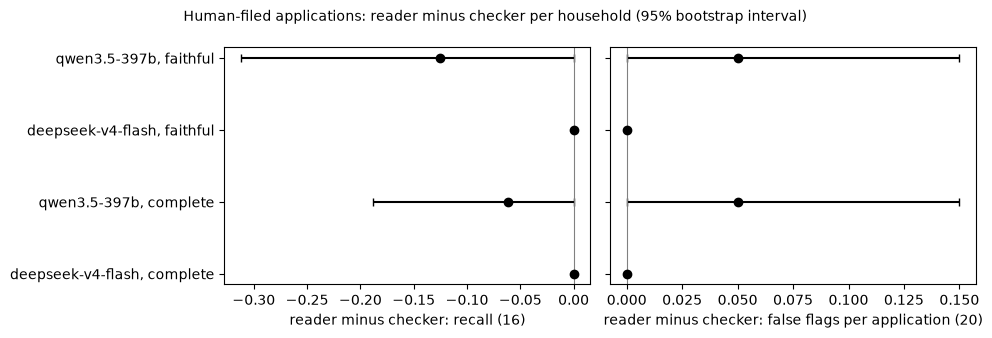

In [49]:

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
pp = paired[paired.packet != "both"]
for ax, measure in zip(axes, ["recall (16)", "false flags per application (20)"]):
    d = pp[pp.measure == measure].reset_index(drop=True)
    y = np.arange(len(d))
    ax.errorbar(d["reader minus checker"], y, xerr=[d["reader minus checker"] - d["95% low"], d["95% high"] - d["reader minus checker"]],
                fmt="o", color="black", capsize=3)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_yticks(y, [f"{r}, {p}" for r, p in zip(d.reader, d.packet)])
    ax.set_xlabel(f"reader minus checker: {measure}")
fig.suptitle("Human-filed applications: reader minus checker per household (95% bootstrap interval)", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "5b-paired-difference.svg", bbox_inches="tight")
plt.show()

### 5c. Reader confidence (proposed: `PROPOSED["reader_confidence"]`)

Mean confidence the reader gave on true and on false flags, human-filed applications. Descriptive only.

In [50]:
if PROPOSED["reader_confidence"]:
    conf = [{"reader": m, "flag": "true" if g in t else "false", "confidence": c}
            for m, fl, t, cf in zip(human.reader, human.flagged, human.truth, human.confidence) if m != "checker"
            for g in fl for c in [cf.get(g)]]
    conf = pd.DataFrame(conf)
    conf_table = conf.groupby(["reader", "flag"]).confidence.agg(["size", "mean", "min", "max"])
    conf_table.to_csv(OUT / "5c-reader-confidence.csv")
    display(conf_table)

size      mean   min   max
reader            flag                             
deepseek-v4-flash false     4  0.742500  0.65  0.92
                  true     29  0.914828  0.70  1.00
qwen3.5-397b      false     6  0.800000  0.50  0.95
                  true     26  0.867308  0.50  1.00

### 5d. AI-filed applications (provenance schema, note A)

Inputs: the 160 first reads in `readers-proposed.jsonl` (80 AI-filed provenance applications: 2 packets x 2 filer models x 20 households, read by both readers). The runner reads provenance applications while `PROPOSED["provenance_schema"]` is on and escape applications otherwise; the reader view is the same for both (part 3d). The truth for an AI-filed application is every group whose filed monthly amount, put alone in place of the verified one, moves the benefit by more than $56 from the QC-correct benefit (an abstained group counts as $0). The checker is run on the same applications for reference. "Not provided" groups: groups the application leaves at "insufficient_evidence"; how often a reader flags one, split by whether the group has a fact.

In [51]:
ai_inputs = {i: a for i, a in read_inputs.items() if a["filer"] != "human"}


def swap_truth(monthly, h):
    verified = {g: float(h[f"verified_{g}"]) for g in F.GROUPS}
    return {g for g in F.GROUPS if abs(P.benefit_of({**verified, g: monthly[g]}, h) - h.qc_benefit) > S.TOL_BENEFIT}


truth_ai = {i: swap_truth(a["app_monthly"], households.loc[a["row"]]) for i, a in ai_inputs.items()}
checker_ai = [{"app_id": i, "reader": "checker", "read": 1, "filer": a["filer"], "schema": a["schema"], "variant": a["variant"],
               "row": a["row"], "valid": True, "confidence": {},
               "flagged": {f["group"] for f in C.check(a["app_monthly"], packets[(a["row"], a["variant"])], households.loc[a["row"]])}}
              for i, a in ai_inputs.items()]
ai = score(pd.concat([reads_ai, pd.DataFrame(checker_ai)], ignore_index=True), truth_ai, "app_id")
print("AI-filed applications read:", reads_ai.app_id.nunique(), "; with at least one group off by more than $56:",
      sum(bool(t) for t in truth_ai.values()))
ai_rp = ai.groupby(["variant", "reader"]).apply(recall_precision)
ai_rp.to_csv(OUT / "5d-ai-recall-precision.csv")
ai_rp.round(3)

AI-filed applications read: 80 ; with at least one group off by more than $56: 24


applications  true groups  flags  true flags  \
variant  reader                                                            
complete checker                    40.0          0.0   14.0         0.0   
         deepseek-v4-flash          40.0          0.0    0.0         0.0   
         qwen3.5-397b               40.0          0.0    3.0         0.0   
faithful checker                    40.0         24.0   40.0        23.0   
         deepseek-v4-flash          40.0         24.0    0.0         0.0   
         qwen3.5-397b               40.0         24.0    3.0         0.0   

                            false flags  recall  precision  
variant  reader                                             
complete checker                   14.0     NaN      0.000  
         deepseek-v4-flash          0.0     NaN        NaN  
         qwen3.5-397b               3.0     NaN      0.000  
faithful checker                   17.0   0.958      0.575  
         deepseek-v4-flash          0.0   0.000        NaN  
         qwen3.5-397b               3.0   0.000      0.000

In [52]:
# Each group off by more than $56 on an AI-filed application: the filer's outcome there, and how many of them each reader flagged.
flag_of = {(i, m): fl for i, m, fl in zip(ai.app_id, ai.reader, ai.flagged)}
truth_groups = pd.DataFrame([{"app_id": i, "group": g} for i, t in truth_ai.items() for g in sorted(t)]).merge(
    groups[["app_id", "group", "scope", "outcome"]], on=["app_id", "group"])
for m in ai.reader.unique():
    truth_groups[f"flagged by {m}"] = [g in flag_of[(i, m)] for i, g in zip(truth_groups.app_id, truth_groups.group)]
truth_groups.to_csv(OUT / "5d-ai-truth-groups.csv", index=False)
truth_groups.groupby(["scope", "outcome"])[[c for c in truth_groups if c.startswith("flagged by")]].agg(["size", "sum"])

flagged by deepseek-v4-flash     flagged by qwen3.5-397b  \
                                             size sum                    size   
scope        outcome                                                            
undocumented A                                 23   0                      23   
             Z                                  1   0                       1   

                         flagged by checker      
                     sum               size sum  
scope        outcome                             
undocumented A         0                 23  23  
             Z         0                  1   0

In [53]:
# Every reader flag on an AI-filed application.
ai[(ai.reader != "checker") & (ai.n_flags > 0)][["app_id", "reader", "flagged", "truth"]]

,app_id,reader,flagged,truth
48,qwen3.5-397b|provenance|complete|A|16881,qwen3.5-397b,{shelter},{}
52,deepseek-v4-flash|provenance|complete|A|16881,qwen3.5-397b,{shelter},{}
55,deepseek-v4-flash|provenance|complete|A|37360,qwen3.5-397b,{shelter},{}
95,qwen3.5-397b|provenance|faithful|A|15847,qwen3.5-397b,{utilities},{earned}
131,qwen3.5-397b|provenance|faithful|A|16881,qwen3.5-397b,{shelter},{}
157,deepseek-v4-flash|provenance|faithful|A|42362,qwen3.5-397b,{shelter},{earned}


In [54]:
not_provided = [{"reader": m, "variant": v, "group has a fact": households.at[r, f"verified_{g}"] > 0, "reader flagged it": g in fl}
                for i, m, v, r, fl in zip(ai.app_id, ai.reader, ai.variant, ai.row, ai.flagged)
                for g in F.GROUPS if ai_inputs[i]["app_monthly"][g] == F.ESCAPE]
not_provided = pd.DataFrame(not_provided).groupby(["reader", "group has a fact"])["reader flagged it"].agg(["size", "sum"]).rename(
    columns={"size": "not-provided groups", "sum": "flagged"})
not_provided.to_csv(OUT / "5d-not-provided-flags.csv")
not_provided

not-provided groups  flagged
reader            group has a fact                              
checker           False                              29       29
                  True                               29       25
deepseek-v4-flash False                              29        0
                  True                               29        0
qwen3.5-397b      False                              29        1
                  True                               29        0

### 5e. Re-reads

10 applications (5 human-filed, 5 AI-filed, drawn by the runner with seed 20261114) read twice more by each reader at temperature 0. Agreement: the flag set is identical across the three reads.

In [55]:
first = pd.concat([reads_core, reads_ai])
re_apps = reads_re.app_id.unique()
three = pd.concat([first[first.app_id.isin(re_apps)], reads_re])
three["flag set"] = three.flagged.map(lambda s: ", ".join(sorted(s)) or "none")
reread = three.pivot_table(index=["app_id", "reader"], columns="read", values="flag set", aggfunc="first")
reread["agree"] = reread.nunique(axis=1) == 1
reread.to_csv(OUT / "5e-rereads.csv")
display(reread.groupby("reader").agree.agg(["size", "sum"]).rename(columns={"size": "applications", "sum": "three reads agree"}))
reread

,applications,three reads agree
reader,,
deepseek-v4-flash,10,10
qwen3.5-397b,10,9


read                                                                     1  \
app_id                                        reader                         
deepseek-v4-flash|provenance|complete|A|14542 deepseek-v4-flash       none   
                                              qwen3.5-397b            none   
deepseek-v4-flash|provenance|complete|A|34791 deepseek-v4-flash       none   
                                              qwen3.5-397b            none   
deepseek-v4-flash|provenance|faithful|A|23521 deepseek-v4-flash       none   
                                              qwen3.5-397b            none   
human|complete|28066                          deepseek-v4-flash     earned   
                                              qwen3.5-397b          earned   
human|complete|30966                          deepseek-v4-flash    shelter   
                                              qwen3.5-397b         shelter   
human|complete|9052                           deepseek-v4-flash       none   
                                              qwen3.5-397b            none   
human|faithful|41978                          deepseek-v4-flash  utilities   
                                              qwen3.5-397b       utilities   
human|faithful|42777                          deepseek-v4-flash    shelter   
                                              qwen3.5-397b         shelter   
qwen3.5-397b|provenance|faithful|A|41978      deepseek-v4-flash       none   
                                              qwen3.5-397b            none   
qwen3.5-397b|provenance|faithful|A|5744       deepseek-v4-flash       none   
                                              qwen3.5-397b            none   

read                                                                     2  \
app_id                                        reader                         
deepseek-v4-flash|provenance|complete|A|14542 deepseek-v4-flash       none   
                                              qwen3.5-397b            none   
deepseek-v4-flash|provenance|complete|A|34791 deepseek-v4-flash       none   
                                              qwen3.5-397b            none   
deepseek-v4-flash|provenance|faithful|A|23521 deepseek-v4-flash       none   
                                              qwen3.5-397b            none   
human|complete|28066                          deepseek-v4-flash     earned   
                                              qwen3.5-397b          earned   
human|complete|30966                          deepseek-v4-flash    shelter   
                                              qwen3.5-397b         shelter   
human|complete|9052                           deepseek-v4-flash       none   
                                              qwen3.5-397b            none   
human|faithful|41978                          deepseek-v4-flash  utilities   
                                              qwen3.5-397b       utilities   
human|faithful|42777                          deepseek-v4-flash    shelter   
                                              qwen3.5-397b         shelter   
qwen3.5-397b|provenance|faithful|A|41978      deepseek-v4-flash       none   
                                              qwen3.5-397b            none   
qwen3.5-397b|provenance|faithful|A|5744       deepseek-v4-flash       none   
                                              qwen3.5-397b            none   

read                                                                     3  \
app_id                                        reader                         
deepseek-v4-flash|provenance|complete|A|14542 deepseek-v4-flash       none   
                                              qwen3.5-397b            none   
deepseek-v4-flash|provenance|complete|A|34791 deepseek-v4-flash       none   
                                              qwen3.5-397b            none   
deepseek-v4-flash|provenance|faithful|A|23521 deepseek-v4-flash       none   
                    

## 6. Format guard

- **Question:** Can the form of a reader input alone tell a human-filed from an AI-filed application?
- **Expected:** no better than chance on format alone (part 3d: one serializer for every application).
- **Method:** the 120 reader inputs actually sent (`reader-inputs.jsonl`: 40 human-filed, 80 AI-filed). First the serializer test of part 3d is re-asserted on all 120: same keys in the same order, every amount whole dollars with a thousands separator or "not provided", no tag, escape token or document id in the application lines, the documents and the allowance line identical to the human-filed input of the same household and packet, and the text equal to `run_pilot.reader_input` on the recorded monthly amounts. Then two classifiers predict human vs AI, each with leave-one-household-out cross-validation (6 inputs per household): a logistic regression with scikit-learn defaults and a lookup rule (the majority filer among training inputs with the same feature row; nothing to set). Features: (a) format-only features: key order, every amount in the whole-dollar format, any decimal point, number of application lines, whether the allowance line is present; and (b) the same plus the blank pattern (which groups read "not provided"). Chance: the majority share (AI-filed, 80 of 120).
- **Result:** the serializer test holds for all 120 inputs. The format-only features take one value on all 120, so both classifiers score 0.667, the majority share. With the blank pattern, the lookup rule scores 0.733 (any "not provided" means AI-filed: 48 of 80 AI-filed inputs have one, no human-filed input does); the logistic regression with defaults still predicts AI-filed for all 120 (0.667).
- **Mismatch:** none.
- **Feeds:** `rq.md` RQ1 (a reader cannot tell the filer from the format).
- **Open questions:** the blank pattern carries the filer's abstentions, which is content, not format: an AI-filed application can be told apart by its "not provided" groups. Options: keep it (it is what an agency would see), or read an abstained group as $0 (then the reader no longer sees the abstention).

In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict

AMOUNT = re.compile(r"^\$\d{1,3}(,\d{3})*$|^not provided$")
TAGS = re.compile(r"insufficient|retrieved_record|applicant_stated|agent_inferred|doc-\d")
inputs = pd.DataFrame(S.read_jsonl(PILOT / "reader-inputs.jsonl"))
human_input = {(a.row, a.variant): a.reader_input for a in inputs[inputs.filer == "human"].itertuples()}
for a in inputs.itertuples():
    lines = S.application_lines(a.reader_input)
    assert [l.split(": ")[0] for l in lines] == [C.GROUP_LABEL[g] for g in F.GROUPS], a.app_id
    assert all(AMOUNT.match(l.split(": ", 1)[1]) for l in lines), a.app_id
    assert not TAGS.search("\n".join(lines)), a.app_id
    assert a.reader_input.split("\n\nDocuments:")[1] == human_input[(a.row, a.variant)].split("\n\nDocuments:")[1], a.app_id
    assert a.reader_input == RUN.reader_input(a.app_monthly, packets[(a.row, a.variant)]), a.app_id
print("serializer test holds for", len(inputs), "reader inputs")


def format_features(text):
    lines = S.application_lines(text)
    values = [l.split(": ", 1)[1] for l in lines]
    return {"key order": int([l.split(": ")[0] for l in lines] == [C.GROUP_LABEL[g] for g in F.GROUPS]),
            "whole-dollar format": int(all(AMOUNT.match(v) for v in values)),
            "decimal point": int(any("." in v for v in values)),
            "application lines": len(lines),
            "allowance line": int("State utility allowances:" in text)}


def blank_features(monthly):
    return {f"{g} not provided": int(monthly[g] in (F.ESCAPE, None)) for g in F.GROUPS}


X_format = pd.DataFrame([format_features(t) for t in inputs.reader_input])
X_blank = pd.concat([X_format, pd.DataFrame([blank_features(m) for m in inputs.app_monthly])], axis=1)
y = (inputs.filer != "human").astype(int)
majority = max(y.mean(), 1 - y.mean())


def lookup_predict(X, y, groups):
    """Leave one household out: predict the majority filer among training inputs with the same feature row
    (the overall training majority if the row is new). No parameter to set."""
    keys = X.astype(str).agg("|".join, axis=1)
    pred = pd.Series(0, index=y.index)
    for g in groups.unique():
        test = groups == g
        train = pd.DataFrame({"key": keys[~test], "y": y[~test]})
        by_key = train.groupby("key").y.mean()
        fallback = train.y.mean()
        pred[test] = [int(by_key.get(k, fallback) > 0.5) for k in keys[test]]
    return pred


guard = []
for name, X in [("format only", X_format), ("format + blank pattern", X_blank)]:
    for clf in ["logistic regression (defaults)", "lookup by feature row"]:
        pred = (cross_val_predict(LogisticRegression(), X, y, groups=inputs.row, cv=LeaveOneGroupOut())
                if clf.startswith("logistic") else lookup_predict(X, y, inputs.row))
        guard.append({"features": name, "classifier": clf, "inputs": len(y), "AI-filed": int(y.sum()),
                      "accuracy (leave one household out)": round((pred == y).mean(), 3),
                      "chance (majority share)": round(majority, 3), "predicted human": int((pred == 0).sum()),
                      "distinct feature rows": len(X.drop_duplicates())})
guard = pd.DataFrame(guard)
guard.to_csv(OUT / "6-format-guard.csv", index=False)
print("format features, distinct values:", X_format.nunique().to_dict())
guard

serializer test holds for 120 reader inputs
format features, distinct values: {'key order': 1, 'whole-dollar format': 1, 'decimal point': 1, 'application lines': 1, 'allowance line': 1}


,features,classifier,inputs,AI-filed,accuracy (leave one household out),chance (majority share),predicted human,distinct feature rows
0,format only,logistic regression (defaults),120,80,0.667,0.667,0,1
1,format only,lookup by feature row,120,80,0.667,0.667,0,1
2,format + blank pattern,logistic regression (defaults),120,80,0.667,0.667,0,8
3,format + blank pattern,lookup by feature row,120,80,0.733,0.667,72,8


In [57]:
# The blank pattern by filer.
pd.crosstab(inputs.filer + " " + inputs.variant, X_blank.filter(like="not provided").sum(axis=1).rename("groups not provided"))

groups not provided,0,1,2
row_0,,,
deepseek-v4-flash complete,12,8,0
deepseek-v4-flash faithful,4,11,5
human complete,20,0,0
human faithful,20,0,0
qwen3.5-397b complete,12,8,0
qwen3.5-397b faithful,4,11,5


## 7. Calls

- **Question:** Do the schemas parse, how often did a call hit the output cap, what did the run cost, and how fast did it go?
- **Expected:** 640 calls (200 core filer, 160 proposed filer, 80 core reader, 160 proposed reader and 40 re-reads), at the planned output cap of 2,048 tokens.
- **Method:** the final record per job id of the four run files, plus the dry run (`dryrun.jsonl`, 4 jobs at 2,048 and the same 4 at 8,192). Valid: status completed, exactly one call to the named tool, JSON arguments that pass the tool's schema (`llm.parse`). Truncated: status incomplete with reason `max_output_tokens`. Credits: `usage.cost`. Seconds per call: `latency_s` (retries included). Throughput: calls per phase / the phase's wall time (first start to last end).
- **Result:** 640 jobs answered (641 records: one job failed on connection errors and was re-run). Valid: 629 of 640 (required 79 of 80, escape 120 of 120, provenance 150 of 160, reader 280 of 280). Invalid: 8 `deepseek-v4-flash` provenance outputs sent `utilities_paid` as a JSON-encoded string; 3 `qwen3.5-397b` outputs put a utility in the housing expenses or left out `how_often`. No call was truncated at 8,192. 113 of the 640 calls used more than 2,048 output tokens and would have been cut at the planned cap (filer: required 20 of 80, escape 18 of 120, provenance 54 of 160; reader 21 of 280); 91 of the 113 are `qwen3.5-397b`. Tokens: 1,220,353 input, 913,994 output (806,796 reasoning). Credits: 2.386 (`qwen3.5-397b` 2.330, `deepseek-v4-flash` 0.056). Median 10.8 seconds per call. Throughput: 640 calls in 31.0 minutes of phase wall time, 1,238 per hour at concurrency 8.
- **Mismatch:** the run used an output cap of 8,192 tokens, not 2,048 (the dry run at 2,048 truncated 2 of 3 filer calls).
- **Feeds:** `rq.md` RQ1 (run cost and time; schema validity).
- **Open questions:** the output cap for the full run; whether to count an output that fails the schema only on an enum (for example a utility type entered as a housing expense) as filed.

In [58]:
RUN_FILES = ["filers-core.jsonl", "filers-proposed.jsonl", "readers-core.jsonl", "readers-proposed.jsonl"]
all_records = [x for f in RUN_FILES for x in S.read_jsonl(PILOT / f)]
calls = pd.DataFrame([x for f in RUN_FILES for x in S.final_records(PILOT / f)])
calls["call type"] = np.where(calls.task == "filer", "filer, " + calls.schema.fillna(""), "reader")
calls["model"] = np.where(calls.task == "filer", calls.filer, calls.reader)
calls["truncated"] = [(d or {}).get("reason") == "max_output_tokens" for d in calls.incomplete_details]
calls["over 2,048 output tokens"] = calls.output_tokens.fillna(0) > 2048
print(len(all_records), "records,", len(calls), "jobs; answered:", int(calls.ok_http.sum()),
      "; output cap used:", sorted(calls.max_output_tokens.unique()))


def call_summary(d):
    return pd.Series({"calls": len(d), "valid": int(d.valid.sum()), "valid share": round(d.valid.mean(), 3),
                      "truncated": int(d.truncated.sum()), "over 2,048 output tokens": int(d["over 2,048 output tokens"].sum()),
                      "max output tokens": int(d.output_tokens.max()), "input tokens": int(d.input_tokens.sum()),
                      "output tokens": int(d.output_tokens.sum()), "reasoning tokens": int(d.reasoning_tokens.sum()),
                      "median output tokens": int(d.output_tokens.median()), "credits": round(d.cost.sum(), 4),
                      "credits per call": round(d.cost.mean(), 6), "median seconds per call": round(d.latency_s.median(), 1),
                      "retries": int(d.retries.sum())})


call_table = pd.concat([calls.groupby(["call type", "model"]).apply(call_summary),
                        calls.groupby("call type").apply(call_summary).assign(model="both").set_index("model", append=True),
                        pd.DataFrame({("all", "both"): call_summary(calls)}).T])
call_table.to_csv(OUT / "7a-calls.csv")
call_table

641 records, 640 jobs; answered: 640 ; output cap used: [np.int64(8192)]


calls  valid  valid share  truncated  \
filer, escape     deepseek-v4-flash   60.0   60.0        1.000        0.0   
                  qwen3.5-397b        60.0   60.0        1.000        0.0   
filer, provenance deepseek-v4-flash   80.0   72.0        0.900        0.0   
                  qwen3.5-397b        80.0   78.0        0.975        0.0   
filer, required   deepseek-v4-flash   40.0   40.0        1.000        0.0   
                  qwen3.5-397b        40.0   39.0        0.975        0.0   
reader            deepseek-v4-flash  140.0  140.0        1.000        0.0   
                  qwen3.5-397b       140.0  140.0        1.000        0.0   
filer, escape     both               120.0  120.0        1.000        0.0   
filer, provenance both               160.0  150.0        0.938        0.0   
filer, required   both                80.0   79.0        0.988        0.0   
reader            both               280.0  280.0        1.000        0.0   
all               both               640.0  629.0        0.983        0.0   

                                     over 2,048 output tokens  \
filer, escape     deepseek-v4-flash                       6.0   
                  qwen3.5-397b                           12.0   
filer, provenance deepseek-v4-flash                       9.0   
                  qwen3.5-397b                           45.0   
filer, required   deepseek-v4-flash                       5.0   
                  qwen3.5-397b                           15.0   
reader            deepseek-v4-flash                       2.0   
                  qwen3.5-397b                           19.0   
filer, escape     both                                   18.0   
filer, provenance both                                   54.0   
filer, required   both                                   20.0   
reader            both                                   21.0   
all               both                                  113.0   

                                     max output tokens  input tokens  \
filer, escape     deepseek-v4-flash             4624.0      117857.0   
                  qwen3.5-397b                  3727.0      119282.0   
filer, provenance deepseek-v4-flash             4570.0      208021.0   
                  qwen3.5-397b                  5234.0      209899.0   
filer, required   deepseek-v4-flash             6528.0       72685.0   
                  qwen3.5-397b                  4992.0       74187.0   
reader            deepseek-v4-flash             2541.0      203777.0   
                  qwen3.5-397b                  4704.0      214645.0   
filer, escape     both                          4624.0      237139.0   
filer, provenance both                          5234.0      417920.0   
filer, required   both                          6528.0      146872.0   
reader            both                          4704.0      418422.0   
all               both                          6528.0     1220353.0   

                                     output tokens  reasoning tokens  \
filer, escape     deepseek-v4-flash        67176.0           53416.0   
                  qwen3.5-397b             94074.0           82691.0   
filer, provenance deepseek-v4-flash       121074.0           94583.0   
                  qwen3.5-397b            211539.0          187003.0   
filer, required   deepseek-v4-flash        42754.0           34221.0   
                  qwen3.5-397b             75818.0           68692.0   
reader            deepseek-v4-flash       114292.0          105536.0   
                  qwen3.5-397b            187267.0          180654.0   
filer, escape     both                    161250.0          136107.0   
filer, provenance both                    332613.0          281586.0   
filer, required   both                    118572.0          102913.0   
reader            both                    301559.0          286190.0   
all               both                    913994.0          806796.0   

                             

In [59]:
invalid = calls[~calls.valid].assign(reason=lambda d: d.invalid_reason.str.slice(0, 110))
invalid_table = invalid.groupby(["call type", "model", "reason"]).size().rename("calls").to_frame()
invalid_table.to_csv(OUT / "7b-invalid-reasons.csv")
invalid_table

calls
call type         model             reason                                                   
filer, provenance deepseek-v4-flash schema_error: utilities_paid: '{"value": "insuf...      1
                                    schema_error: utilities_paid: '{"value": "insuf...      1
                                    schema_error: utilities_paid: '{"value": ["Heat...      1
                                    schema_error: utilities_paid: '{"value": ["Heat...      5
                  qwen3.5-397b      schema_error: housing_expenses/0: 'how_often' i...      1
                                    schema_error: housing_expenses/1/type_of_expens...      1
filer, required   qwen3.5-397b      schema_error: housing_expenses/0/type_of_expens...      1

In [60]:
# Dry run: the same four jobs at the planned cap and at 8,192.
dry = pd.DataFrame(S.read_jsonl(PILOT / "dryrun.jsonl"))
dry_table = dry[["task", "schema", "request_model", "max_output_tokens", "status", "output_tokens", "reasoning_tokens", "valid", "invalid_reason"]]
dry_table.to_csv(OUT / "7c-dryrun.csv", index=False)
dry_table

,task,schema,request_model,max_output_tokens,status,output_tokens,reasoning_tokens,valid,invalid_reason
0,filer,required,deepseek-v4-flash,2048,completed,906,738,True,NaN
1,filer,provenance,deepseek-v4-flash,2048,incomplete,2048,2048,False,status_incomplete
2,reader,NaN,qwen3.5-397b,2048,completed,1518,1490,True,NaN
3,filer,escape,qwen3.5-397b,2048,incomplete,2048,1934,False,status_incomplete
4,filer,required,deepseek-v4-flash,8192,completed,865,695,True,NaN
5,filer,provenance,deepseek-v4-flash,8192,completed,1855,1550,False,"schema_error: utilities_paid: '{""value"": ""insu..."
6,reader,NaN,qwen3.5-397b,8192,completed,3162,3131,True,NaN
7,filer,escape,qwen3.5-397b,8192,completed,2883,2705,True,NaN


In [61]:
# Throughput per phase (wall time from the first start to the last end in the phase, all records).
rec = pd.DataFrame(all_records)
phases = rec.groupby("phase").agg(records=("job_id", "size"), start=("t_start", "min"), end=("t_end", "max"))
phases["jobs"] = calls.groupby("phase").size()
phases["wall minutes"] = ((phases.end - phases.start) / 60).round(2)
phases["calls per hour"] = (phases.jobs / (phases.end - phases.start) * 3600).round(0)
phases = phases.reindex(["core-filers", "core-readers", "proposed-filers", "proposed-readers", "rereads"])
phases.loc["all phases"] = [phases.records.sum(), np.nan, np.nan, phases.jobs.sum(), phases["wall minutes"].sum(),
                            round(phases.jobs.sum() / phases["wall minutes"].sum() * 60)]
phases = phases.drop(columns=["start", "end"])
pf = rec[rec.phase == "proposed-filers"].sort_values("t_start")
print("proposed-filers without the later re-run of one job:", round((pf.t_end.iloc[:-1].max() - pf.t_start.min()) / 60, 2), "minutes")
PILOT_RATE = float(phases.loc["all phases", "calls per hour"])
phases.to_csv(OUT / "7d-throughput.csv")
phases

proposed-filers without the later re-run of one job: 9.51 minutes


,records,jobs,wall minutes,calls per hour
phase,,,,
core-filers,200,200,7.20,1667.0
core-readers,80,80,4.13,1161.0
proposed-filers,161,160,11.25,853.0
proposed-readers,160,160,7.49,1282.0
rereads,40,40,0.95,2524.0
all phases,641,640,31.02,1238.0


## 8. Call-budget calculator (proposed: `PROPOSED["budget_calculator"]`)

- **Question:** How many calls and hours does a plan take?
- **Expected:** the pilot plan gives 640 calls. The full-run plan (2,094 households: the 616 of the human arm plus 1,478 comparison households, 01 part 7): about 13,800 filer and 25,100 reader calls, about 40,000 in all, about 17 hours at the 03 part 1 rate of 2,283 calls per hour.
- **Method:** `pilot_score.budget`: filer calls = households x packets x notes x filer models per cell; reader calls = applications (households x packets x filers, 1 for human-filed) x readers, plus re-reads. Hours at the pilot's measured rate (part 7), at 2,283 per hour (03 part 1) and at the account ceiling of 50 calls per minute (3,000 per hour).
- **Result:** pilot plan 640 calls, equal to the calls run. Full-run plan: 13,796 filer calls, 25,128 reader calls plus 1,200 re-reads (26,328), 40,124 in all; 17.6 hours at 2,283 per hour, 13.4 at the ceiling, 32.4 at the pilot's measured 1,238 per hour.
- **Mismatch:** none in the call counts (13,796 vs about 13,800; 25,128 vs about 25,100; 40,124 vs about 40,000). Hours: 17.6 at 2,283 per hour against about 17; at the pilot's own rate the plan takes 32.4 hours.
- **Feeds:** `rq.md` RQ1 (run size and time).
- **Open questions:** whether the full run keeps note B and the linkability packet (neither is in the plan below); the concurrency to run at (the pilot ran 8 at a time, below the ceiling).

In [62]:
if PROPOSED["budget_calculator"]:
    RATES = {"pilot rate": PILOT_RATE, "03 part 1 rate (2,283/h)": 2283, "ceiling (3,000/h)": 3000}
    pilot_filers = [dict(label="required, complete + faithful, note A", households=20, packets=2, filers=2),
                    dict(label="escape, complete + faithful, note A", households=20, packets=2, filers=2),
                    dict(label="escape, faithful, note B", households=20, packets=1, filers=2),
                    dict(label="provenance, complete + faithful, note A", households=20, packets=2, filers=2),
                    dict(label="provenance, faithful, note B", households=20, packets=1, filers=2),
                    dict(label="provenance, faithful_linkability, note A", households=20, packets=1, filers=2)]
    pilot_readers = [dict(label="human-filed, 2 packets", households=20, packets=2, filers=1),
                     dict(label="AI provenance, 2 packets x 2 filer models", households=20, packets=2, filers=2)]
    pilot_cells, pilot_budget = S.budget(pilot_filers, pilot_readers, n_readers=2, rereads=40, rates=RATES)
    assert pilot_budget.loc["all", "calls"] == len(calls), (pilot_budget.loc["all", "calls"], len(calls))
    N_FULL, N_ARM = 616 + 1478, 616
    full_filers = [dict(label="provenance x 2 packets x 2 models", households=N_FULL, packets=2, filers=2),
                   dict(label="escape x faithful x 2 models", households=N_FULL, packets=1, filers=2),
                   dict(label="required x faithful x 2 models (the 616)", households=N_ARM, packets=1, filers=2)]
    full_readers = [dict(label="human-filed x 2 packets", households=N_FULL, packets=2, filers=1),
                    dict(label="AI provenance x 2 packets x 2 filer models", households=N_FULL, packets=2, filers=2)]
    full_cells, full_budget = S.budget(full_filers, full_readers, n_readers=2, rereads=1200, rates=RATES)
    pd.concat({"pilot": pilot_cells, "full run": full_cells}).to_csv(OUT / "8-budget-cells.csv")
    budget_table = pd.concat({"pilot": pilot_budget, "full run": full_budget}).round(1)
    budget_table.to_csv(OUT / "8-budget.csv")
    display(full_cells)
    display(budget_table)

,task,cell,calls
0,filer,provenance x 2 packets x 2 models,8376
1,filer,escape x faithful x 2 models,4188
2,filer,required x faithful x 2 models (the 616),1232
3,reader,human-filed x 2 packets,8376
4,reader,AI provenance x 2 packets x 2 filer models,16752
5,reader,re-reads,1200


calls  hours at pilot rate  \
         task                                 
pilot    filer     360                  0.3   
         reader    280                  0.2   
         all       640                  0.5   
full run filer   13796                 11.1   
         reader  26328                 21.3   
         all     40124                 32.4   

                 hours at 03 part 1 rate (2,283/h)  hours at ceiling (3,000/h)  
         task                                                                   
pilot    filer                                 0.2                         0.1  
         reader                                0.1                         0.1  
         all                                   0.3                         0.2  
full run filer                                 6.0                         4.6  
         reader                               11.5                         8.8  
         all                                  17.6                        13.4

In [63]:
if PROPOSED["budget_calculator"]:
    expected = pd.DataFrame({"expected": [13_800, 25_100, 40_000, 17],
                             "computed": [full_budget.loc["filer", "calls"], full_budget.loc["reader", "calls"] - 1200,
                                          full_budget.loc["all", "calls"], full_budget.loc["all", "hours at 03 part 1 rate (2,283/h)"]]},
                            index=["filer calls", "reader calls without re-reads", "all calls", "hours at 2,283/h"])
    expected["computed"] = expected.computed.round(1)
    expected.to_csv(OUT / "8-budget-vs-expected.csv")
    display(expected)

,expected,computed
filer calls,13800,13796.0
reader calls without re-reads,25100,25128.0
all calls,40000,40124.0
"hours at 2,283/h",17,17.6
